In [2]:
library(ggplot2)
library(reshape)
library(gplots)
library(tidyr)
library(dplyr)

setwd("~/Moore-Lab/Papers/3D-Genome/")

# Main Figures

## Figure 1

### Panel C - Cross-assay support

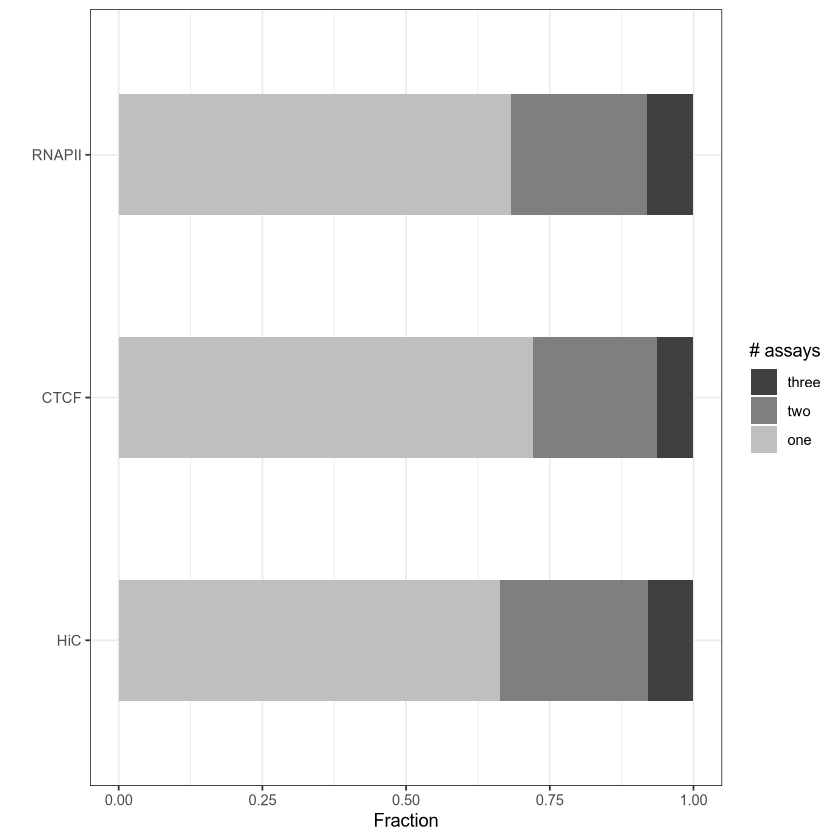

In [14]:
data = read.table("1_General-Comparisons/Summary-Assay-Overlap.txt")
d = data[data$V1 == "MCF-7",]

one=d$V8
two=d$V5+d$V6+d$V7
three=d$V4

modData=data.frame(d$V2, one, two, three)

meltedData=melt(modData, id="d.V2")

meltedData$variable = factor(meltedData$variable, levels=c("three","two","one"))
meltedData$d.V2 = factor(meltedData$d.V2, levels=c("HiC","CTCF","RNAPII"))

ggplot(meltedData, aes(y=d.V2, x=value, fill=variable)) + 
    geom_bar(stat="identity", position="fill", width=0.5) + 
    ylab("") + xlab("Fraction") +
    scale_fill_manual(name="# assays",values=c("gray25","gray50","gray75")) + 
    theme_bw()

### Panel D - Overlap with CTCF-bound cCREs

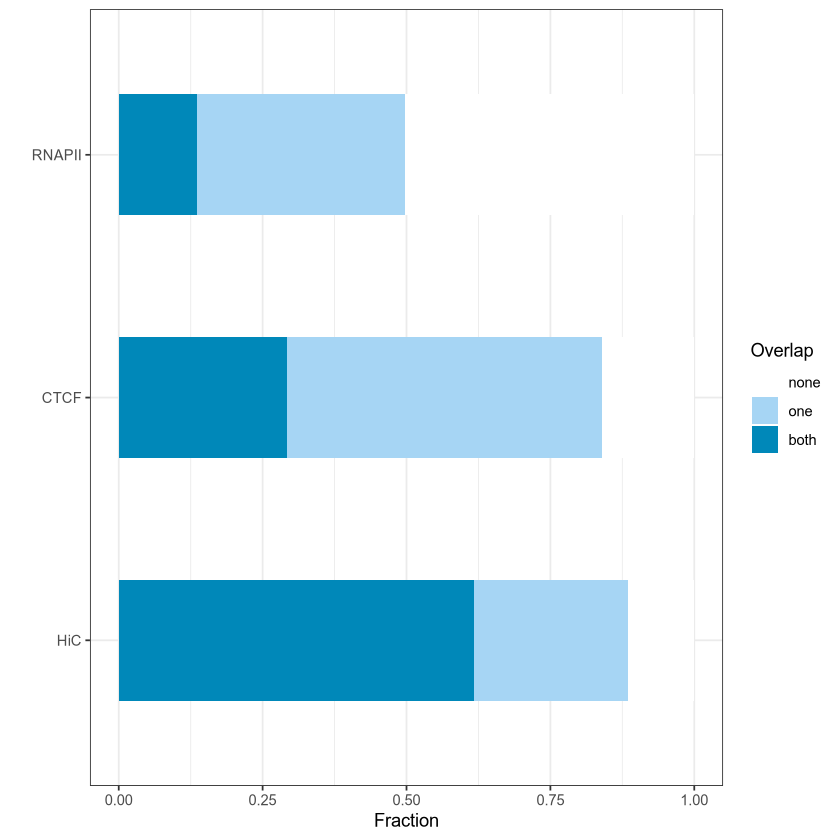

In [7]:
data = read.table("1_General-Comparisons/Summary-CTCF-Anchor-Overlap.txt")

d = data[data$V1 == "MCF-7",]

none=d$V5-d$V3
one=d$V3-d$V4
both=d$V4

modData=data.frame(d$V2, both, one, none)

meltedData=melt(modData, id="d.V2")

meltedData$variable = factor(meltedData$variable, levels=c("none","one","both"))
meltedData$d.V2 = factor(meltedData$d.V2, levels=c("HiC","CTCF","RNAPII"))

ggplot(meltedData, aes(y=d.V2, x=value, fill=variable)) + 
    geom_bar(stat="identity", position="fill", width=0.5) + 
    ylab("") + xlab("Fraction") +
    scale_fill_manual(name="Overlap",values=c("white","#a6d5f4","#0088b9")) + 
    theme_bw()


### Panel E - Overlap with cCRE classes

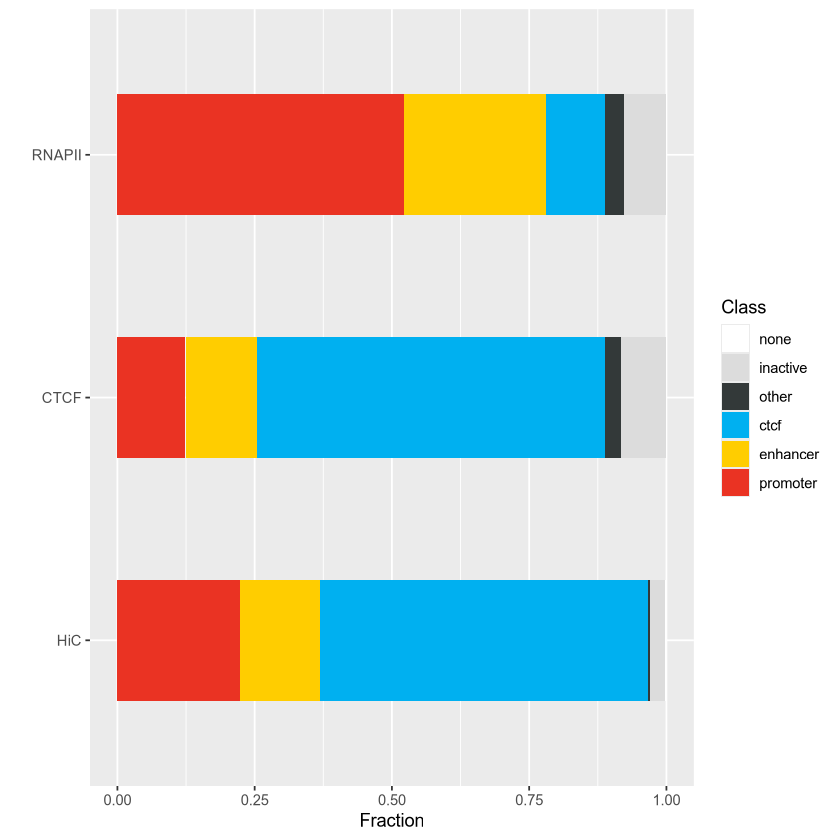

In [8]:
data = read.table("1_General-Comparisons/Summary-cCRE-Overlap.txt")

d = data[data$V1 == "MCF-7",][,2:8]
names(d) = c("assay", "promoter", "enhancer", "ctcf", "other", "inactive", "none")

melted = melt(d, id="assay")
melted$assay = factor(melted$assay, levels=c("HiC","CTCF","RNAPII"))
melted$variable = factor(melted$variable, levels=c("none","inactive","other","ctcf","enhancer","promoter"))

ggplot(melted, aes(y=assay, x=value, fill=variable)) + geom_bar(width=0.5,stat="identity", position="fill") +
    scale_fill_manual(name="Class", values=rev(c("#ea3323","#ffcd00","#00b0f0","#333939","#dcdcdc","white"))) +
    xlab("Fraction") + ylab("")



## Figure 2

### Panel A - Categories of promoter-centric interactions

Var1,Freq
<fct>,<int>
P-C,19158
P-E,12133
P-P,9840


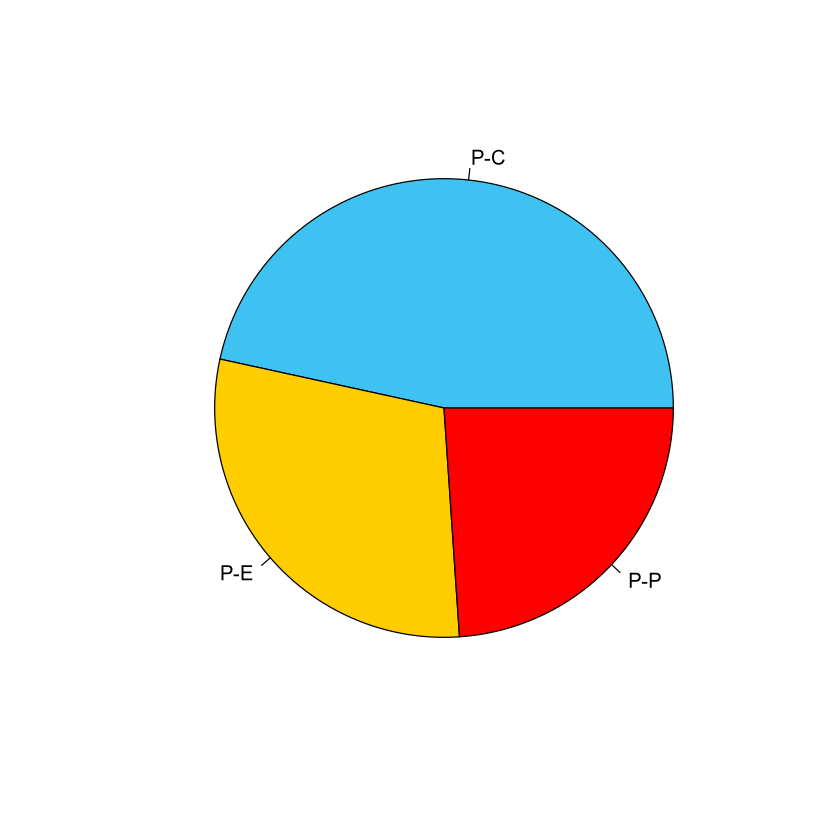

In [15]:
data = read.table("2_Promoter-Centric/Promoter-Centric-Annotations/MCF-7.Promoter-Links.txt")

data = data.frame(lapply(data, function(x) {gsub("P-Ed", "P-E", x)}))
data = data.frame(lapply(data, function(x) {gsub("P-Ep", "P-E", x)}))


filtered = data[data$V8 == "P-P" | data$V8 == "P-E" | data$V8 == "P-C",]
filteredCounts = data.frame(table(filtered$V8))

pie(filteredCounts$Freq, filteredCounts$Var1, col=c("#3ec2f2", "#ffcd00", "red"))

filteredCounts

### Panel B - Breakdown of candidate archictural interactions

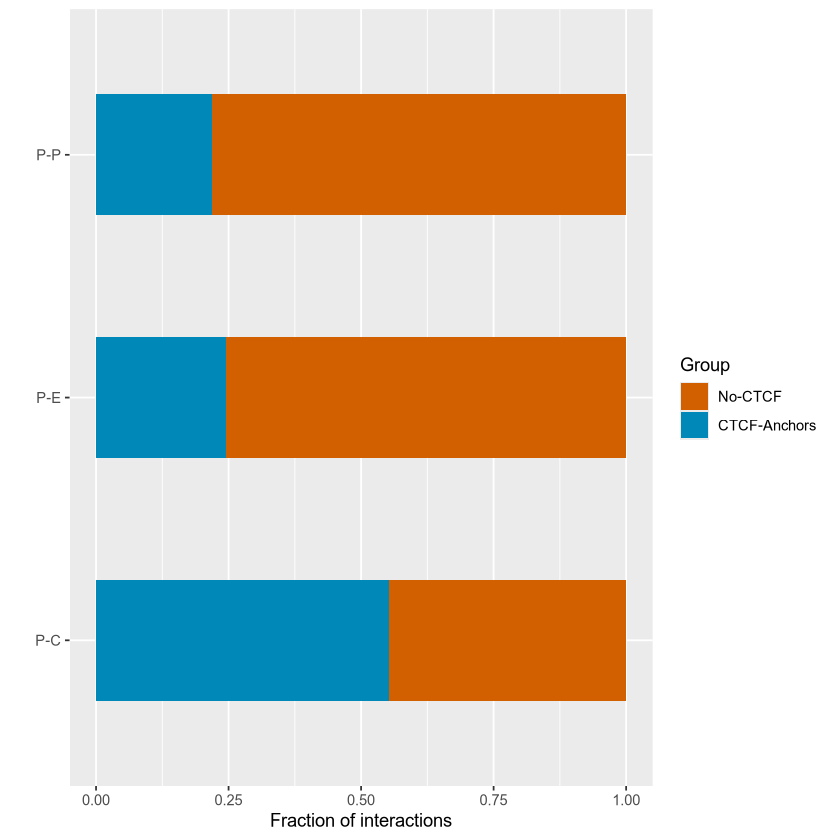

In [139]:
data = read.table("2_Promoter-Centric/Promoter-Centric-Annotations/MCF-7.Promoter-Links.txt")

data = data.frame(lapply(data, function(x) {gsub("P-Ed", "P-E", x)}))
data = data.frame(lapply(data, function(x) {gsub("P-Ep", "P-E", x)}))



filtered = data[data$V8 == "P-P" | data$V8 == "P-E" | data$V8 == "P-C",]

filtered$V9 = factor(filtered$V9, levels=c("No-CTCF","CTCF-Anchors"))

ggplot(filtered, aes(y=V8, fill=V9)) + geom_bar(position="fill", width=0.5) + 
    scale_fill_manual(name="Group", values=c("#d36000","#0088b9")) + 
    xlab("Fraction of interactions") + ylab("")

### Panel C - Recurrance of Promoter-centric interactions across cell types

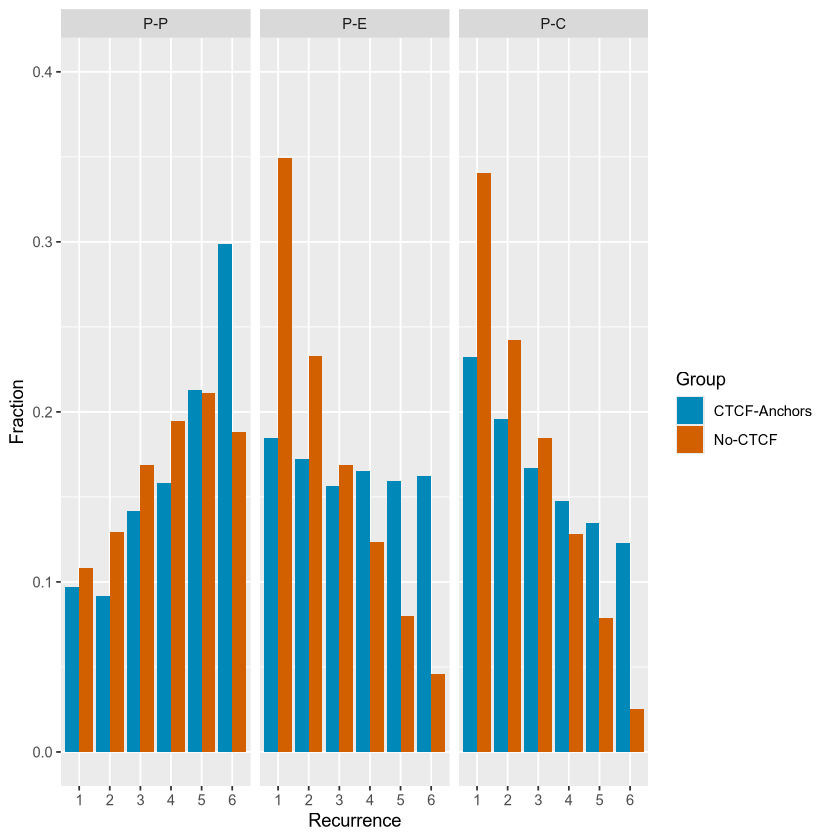

In [158]:
data = read.table("2_Promoter-Centric/Recurrance-Across-Cell-Lines/MCF-7.Recurrance-Counts.txt", sep = "\t")


data = separate(data, V1, into = c("A", "B", "C", "D"), sep = "__")
data$C = factor(data$C, levels=c("P-P","P-E", "P-C"))

plot_data <- data %>%
    count(C, D, V2) %>%
    group_by(C, D) %>%
    mutate(Fraction = n / sum(n))

ggplot(plot_data, aes(x = factor(V2), y = Fraction, fill = D)) +
    geom_col(position = "dodge") +
    facet_wrap(~C) +
    scale_fill_manual(name = "Group", values = c("#0088b9", "#d36000")) + 
    labs(x = "Recurrence", y = "Fraction") +
    coord_cartesian(y=c(0,0.4))

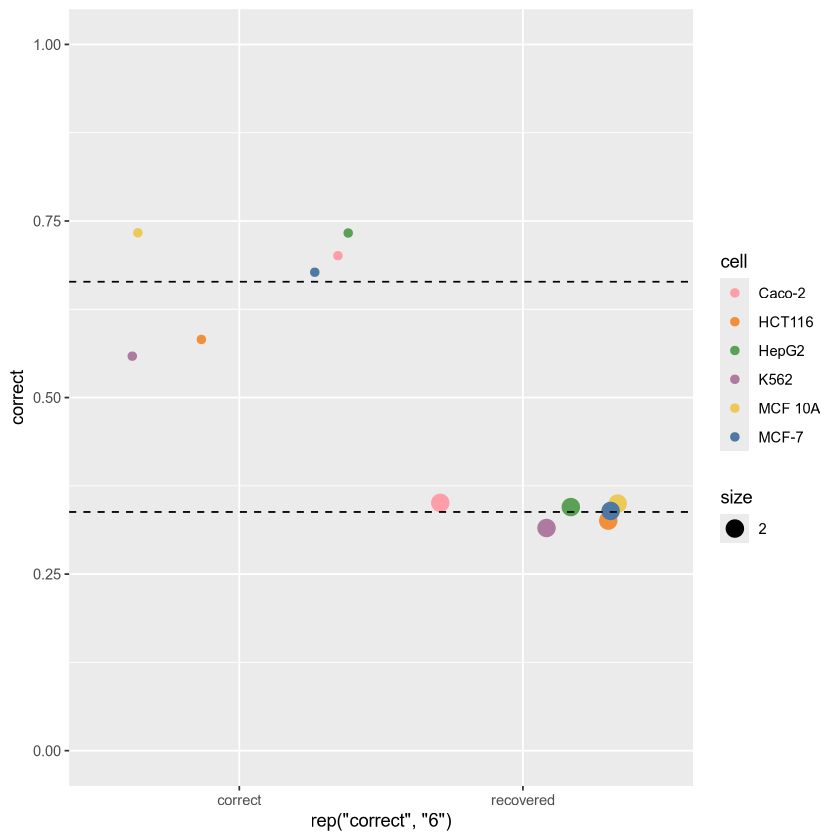

In [10]:
data=read.table("2_Promoter-Centric/Closest-Gene-Evaluation/Closest-Expressed-Method-Summary.txt", header=T, sep="\t")

ggplot(data, aes(x=rep("correct","6"), y=correct, color=cell)) + geom_jitter(size=2) + geom_jitter(data=data, aes(x=rep("recovered","6"), y=recovered, color=cell, size=2)) +
    scale_color_manual(values=c("#fe9ea8","#f18f3b","#5aa155","#af7aa0","#edc958","#4e79a5")) + coord_cartesian(y=c(0,1)) +
    geom_hline(yintercept=0.664, linetype="dashed") + geom_hline(yintercept=0.338, linetype="dashed")


## Figure 3

### Panel A - Recurrance of MCF-7 candidate architectural P-E interactions

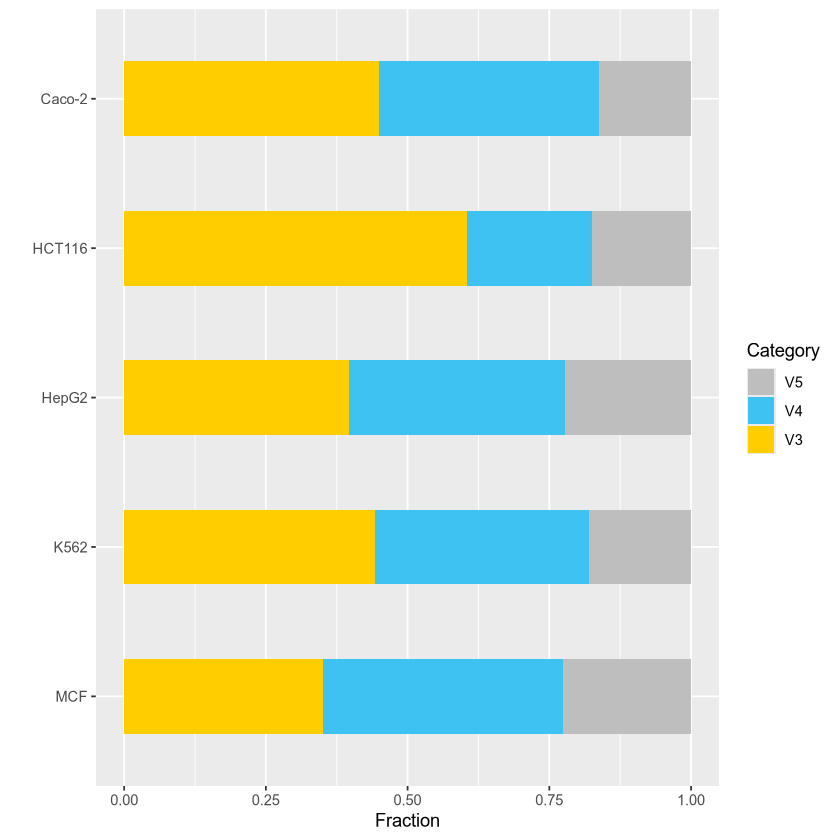

In [93]:
data = read.table("3_Dual-Elements/Summary-Arc-P-E-Recurrance.txt")
filtered = data[data$V1 == "MCF-7" & data$V2 != "MCF-7",]


filtered$V2 = factor(filtered$V2, levels=c("MCF","K562", "HepG2", "HCT116","Caco-2"))

melted = melt(filtered[,2:5], id="V2")

melted$variable = factor(melted$variable, levels=c("V5","V4", "V3"))
ggplot(melted, aes(y=V2, x=value, fill=variable)) + 
    geom_bar(width= 0.5, stat="identity", position="fill") +
    scale_fill_manual(name="Category",values=c("gray","#3ec2f2", "#ffcd00")) + 
    ylab("") + xlab("Fraction")

### Panel C - STARR scores of dual E/C elements


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  data$V2 and data$V3 

                background ctcf-only-state enhancer-state
ctcf-only-state 2.3e-06    -               -             
enhancer-state  2.3e-14    0.0007          -             
K562-enhancer   < 2e-16    0.0175          0.0104        

P value adjustment method: fdr 

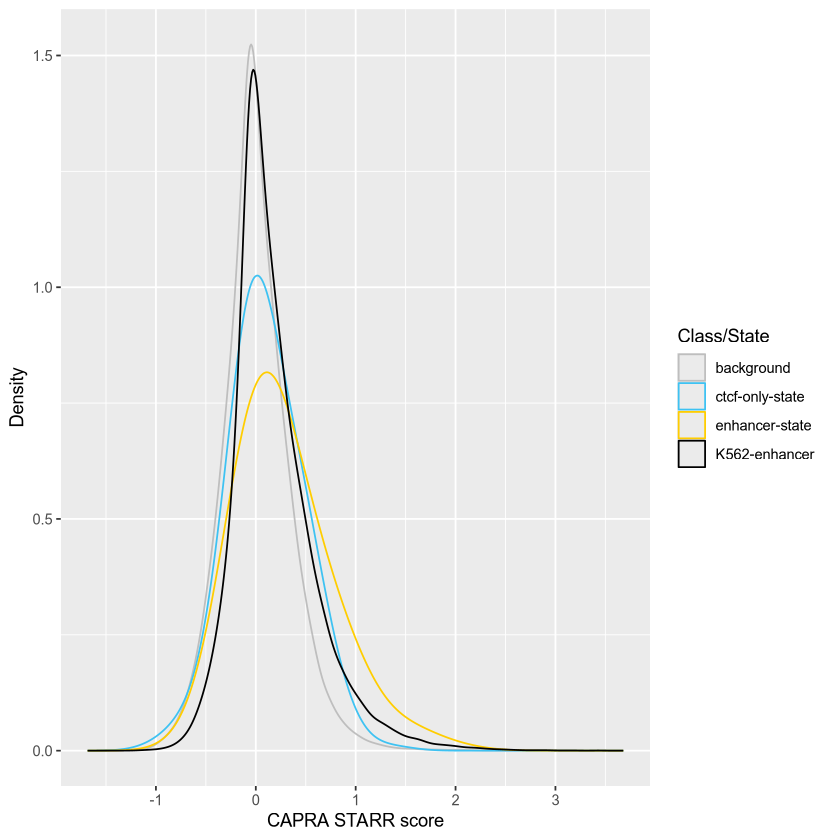

In [90]:
data = read.table("3_Dual-Elements/CAPRA-Scores/K562-CAPRA-Scores.txt")

ggplot(data, aes(x=V2, color=V3)) + geom_density(adjust=2) +
    scale_color_manual(name="Class/State", values=c("gray","#3ec2f2", "#ffcd00", "black")) +
    xlab("CAPRA STARR score") + ylab("Density")

pairwise.wilcox.test(data$V2, data$V3, p.adj="fdr")

### Panel D - Increase in high contributing bases


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  slice$V7 and slice$V9 

               ctcf-only-state
enhancer-state 3.5e-13        

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  slice$V7 and slice$V9 

               ctcf-only-state
enhancer-state 2.4e-08        

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  slice$V7 and slice$V9 

               ctcf-only-state
enhancer-state 3.1e-08        

P value adjustment method: holm 

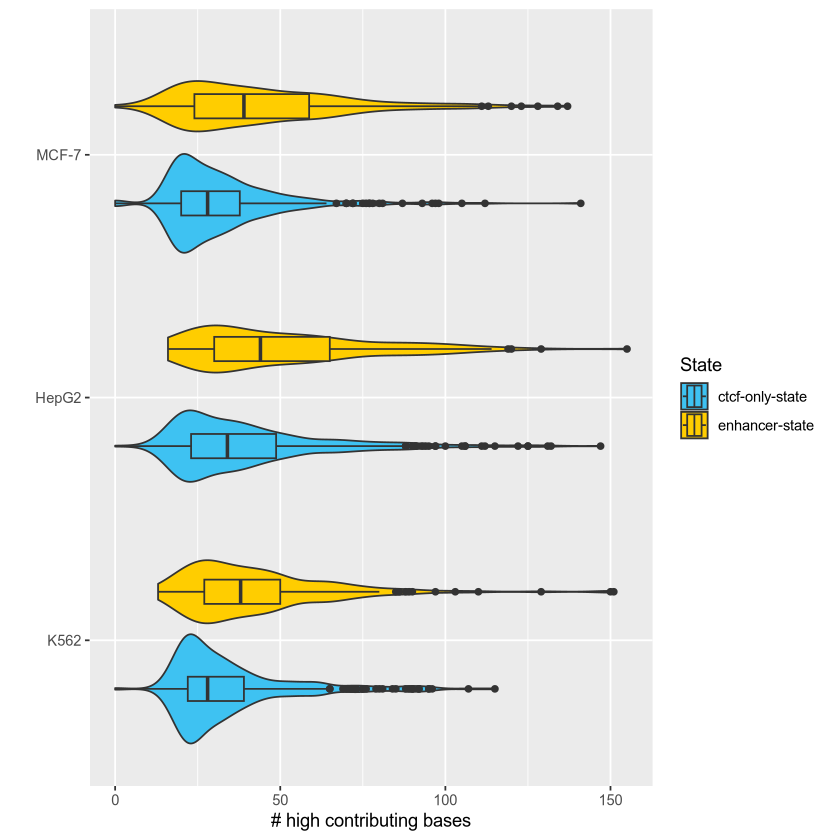

In [110]:
data = read.table("3_Dual-Elements/ChromBPNet//Attribution-Calculations//Combo-ChromBPNet-EC-Attributions.txt")

pd = position_dodge(width = 0.8)

data$V10 = factor(data$V10, levels=c("K562","HepG2", "MCF-7"))

ggplot(data, aes(x=V7, y=V10, fill=V9)) + geom_violin(position=pd) + 
    geom_boxplot(position=pd, width=0.2) + 
    scale_fill_manual(name="State",values=c("#3ec2f2", "#ffcd00")) +
    xlab("# high contributing bases") + ylab("")


slice = data[data$V10 == "MCF-7",]
pairwise.wilcox.test(slice$V7, slice$V9)

slice = data[data$V10 == "HepG2",]
pairwise.wilcox.test(slice$V7, slice$V9)

slice = data[data$V10 == "K562",]
pairwise.wilcox.test(slice$V7, slice$V9)

### Panel E - Number overlapping TF summits


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  slice$V2 and slice$V3 

               ctcf-only-state
enhancer-state 2.2e-10        

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  slice$V2 and slice$V3 

               ctcf-only-state
enhancer-state <2e-16         

P value adjustment method: holm 

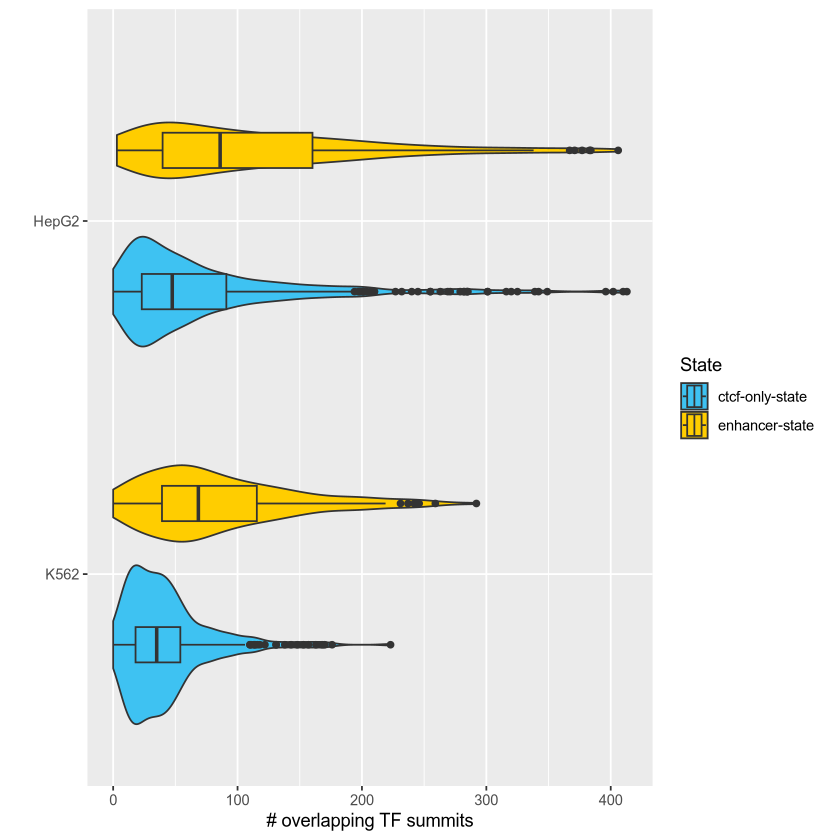

In [114]:
data = read.table("3_Dual-Elements/TF-Overlap/Combo-TF-Summit-Overlap.txt")

pd = position_dodge(width = 0.8)

data$V4 = factor(data$V4, levels=c("K562","HepG2"))

ggplot(data, aes(x=V2, y=V4, fill=V3)) + geom_violin(position=pd) + 
    geom_boxplot(position=pd, width=0.2) + 
    scale_fill_manual(name="State",values=c("#3ec2f2", "#ffcd00")) +
    xlab("# overlapping TF summits") + ylab("")

slice = data[data$V4 == "HepG2",]
pairwise.wilcox.test(slice$V2, slice$V3)

slice = data[data$V4 == "K562",]
pairwise.wilcox.test(slice$V2, slice$V3)

## Figure 4

### Panel A - ChromBPNet attribution scores at experimentally supported motif sites in MCF-7

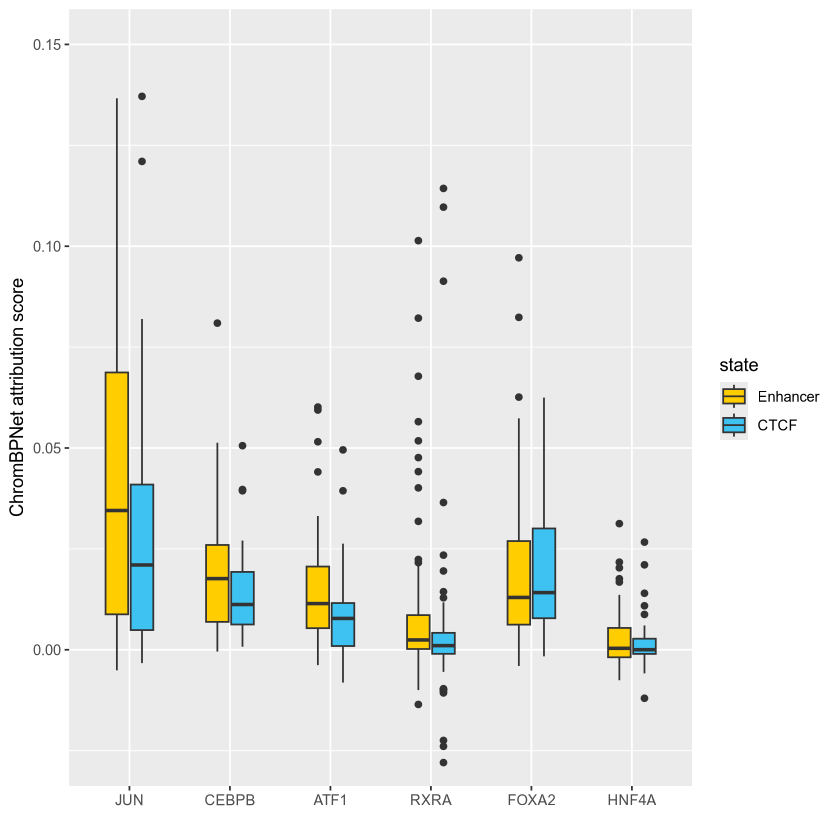

In [25]:
attrib = read.table("4_TF-Conservation/Motif-Attribution//Motif-Attribution-MCF-7.txt")

filtered = attrib[attrib$V3 == "JUN" | attrib$V3 == "CEBPB" | attrib$V3 == "ATF1" | attrib$V3 == "RXRA" | 
                  attrib$V3 == "FOXA2" | attrib$V3 == "HNF4A",]
filtered$V3 = factor(filtered$V3, levels=c("JUN","CEBPB","ATF1", "RXRA", "FOXA2","HNF4A"))
filtered$V4 = factor(filtered$V4, levels=c("Enhancer","CTCF"))

#pdf("00_Data/Raw-Figures/Figure-4A.MCF-7-ChromBPNet-Attribution.pdf", width=7, height=4.5)
ggplot(filtered, aes(x=V3, fill=V4, y=V2))+geom_boxplot(width=0.5) + coord_cartesian(y=c(-0.025,0.15)) +
    scale_fill_manual(name="state",values=c("#ffcd00","#3ec2f2")) + xlab("") + ylab("ChromBPNet attribution score")
#dev.off()

### Panel B - ChromBPNet attribution scores across 6 cell lines for select TFs

In [49]:
summary = read.table("4_TF-Conservation/Motif-Attribution/Summary-Motif-Attribution.txt")

filtered = summary[attrib$V2 == "JUN" | attrib$V2 == "CEBPB" | attrib$V2 == "ATF1" | attrib$V2 == "RXRA" | 
                  attrib$V2 == "FOXA2" | attrib$V2 == "HNF4A",]
filtered$V2 = factor(filtered$V2, levels=c("JUN","CEBPB","ATF1", "RXRA", "FOXA2","HNF4A"))
filtered$V1 = factor(filtered$V1, levels=c("MCF-7","HCT116","K562", "MCF", "HepG2","Caco-2"))

filteredMatrix = xtabs(V3-V4 ~ V1 + V2, data = filtered)

colors=colorRampPalette(c("#2d6993", "#3ec2f2", "white","#ffcd00", "#bd9e33"))(200)

pdf("00_Data/Raw-Figures/Figure-4B.Heatmap-ChromBPNet-Attribution.pdf", width=6, height=5)
heatmap.2(filteredMatrix, col=colors, breaks=seq(-0.01,0.01,0.0001), dendrogram="none", Colv="NA", Rowv="NA", trace="none")
dev.off()

pdf 
  2

### Panel C - Example locus

Availble on the UCSC genome browser track hub: 

### Panel D - Aggregation plot of conservation at TF motifs

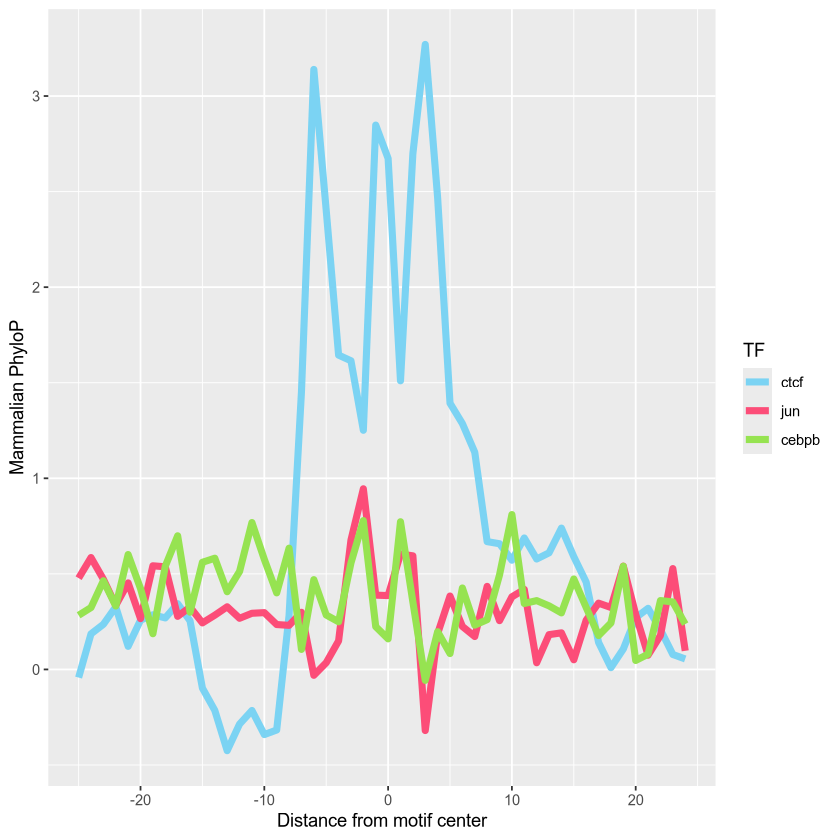

In [53]:
ctcf=read.table("4_TF-Conservation/Aggregation-Signal/CTCF-Signal.txt", sep="\t")
jun=read.table("4_TF-Conservation/Aggregation-Signal/JUN-Signal.txt", sep="\t")
cebpb=read.table("4_TF-Conservation/Aggregation-Signal/CEBPB-Signal.txt", sep="\t")

ctcf=ctcf[,7:56]
jun=jun[,7:56]
cebpb=cebpb[,7:56]

df=data.frame(x=seq(-25,24,1), ctcf=colMeans(ctcf), jun=colMeans(jun), cebpb=colMeans(cebpb))
e=melt(df, id="x")

#pdf("00_Data//Raw-Figures/Figure-4D.Conservation-Profiles.pdf", width=6, height=4.5)
ggplot(e, aes(x=x, y=value, color=variable, group=variable)) + geom_line(linewidth=2) + 
    scale_color_manual(name="TF",values=c("#7bd3f3","#fc4d78","#96e351")) + 
    xlab("Distance from motif center") + ylab("Mammalian PhyloP")
#dev.off()

### Panel E - Paired Sequence similarity

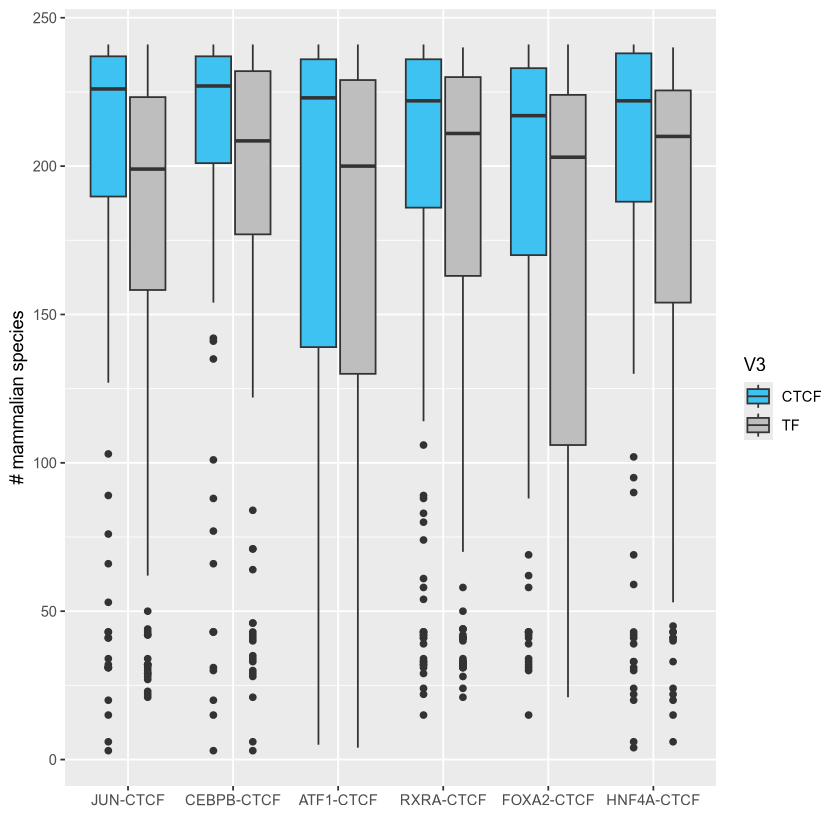

In [62]:
data=read.table("4_TF-Conservation/Example-TF-Paired-Similarity.txt")

data$V2 = factor(data$V2, levels=c("JUN-CTCF","CEBPB-CTCF","ATF1-CTCF", "RXRA-CTCF", "FOXA2-CTCF","HNF4A-CTCF"))

#pdf("00_Data/Raw-Figures/Figure-4E.Paried-TF-Similarity-Score.pdf", width=7, height=4.5)
ggplot(data, aes(x=V2, y=V1, fill=V3))+geom_boxplot() + scale_fill_manual(values=c("#3ec2f2", "gray")) +
    xlab("") + ylab("# mammalian species")
#dev.off()


### Panel F

This circle conservation plot was created using the script XXX which can be found in the Toolkit

## Figure 5

### Panel A

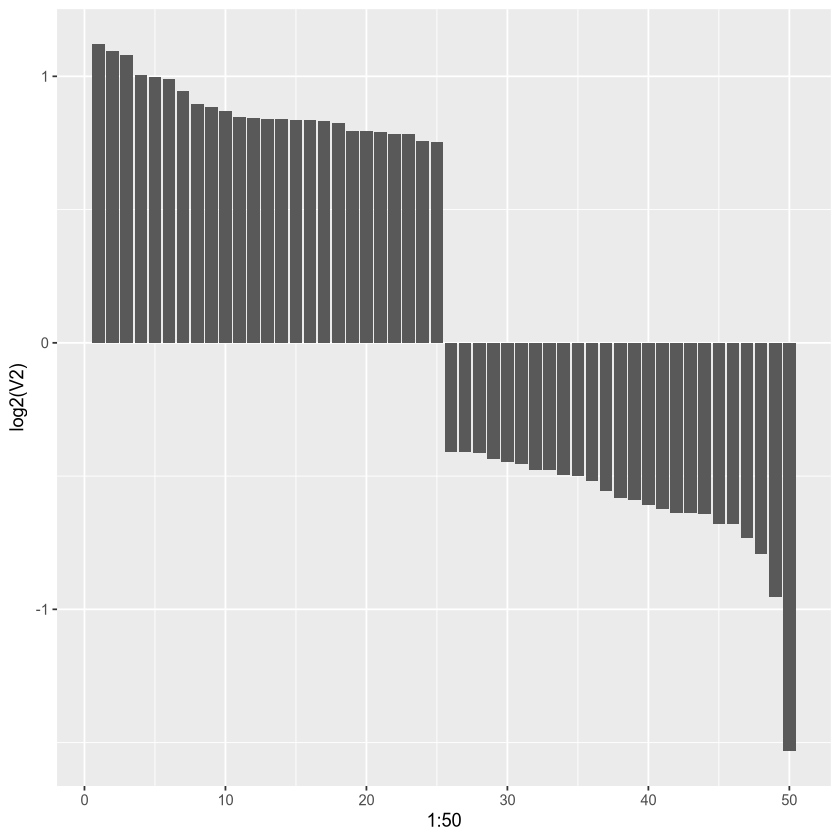

In [18]:
data = read.table("5_Biological-Spectrum/H3K27ac-Enrichment/Top-Bottom-25.txt")

ggplot(data, aes(x=1:50, y=log2(V2))) + geom_bar(stat="identity")


### Panel C

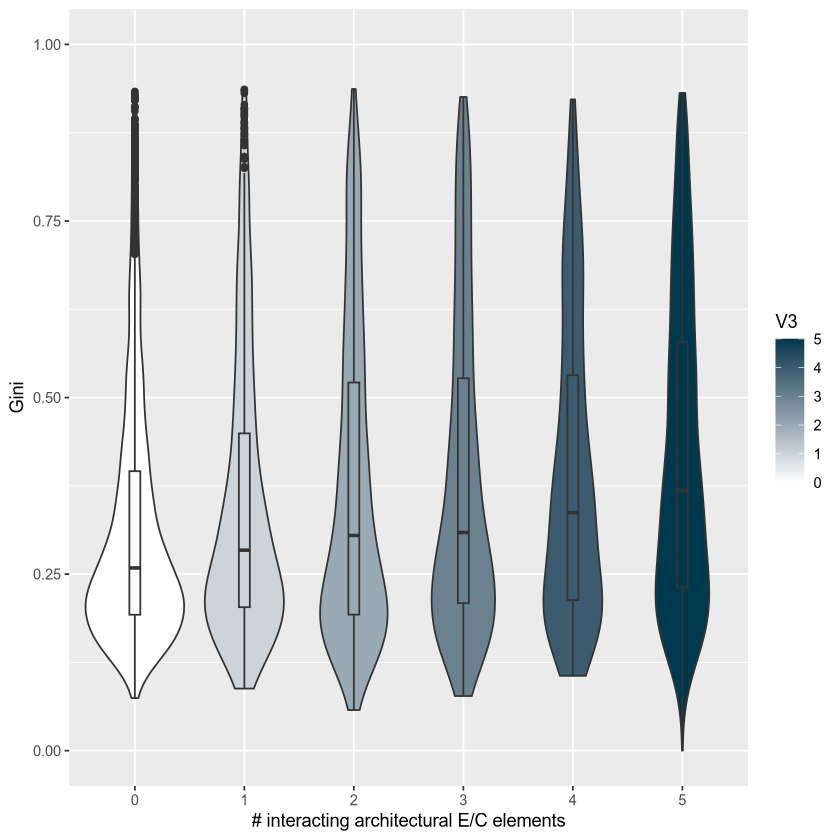

In [28]:
data = read.table("5_Biological-Spectrum/Gini/MCF-7-By-Count-Gini.txt")

ggplot(data, aes(x=as.factor(V3), y=V2, fill=V3)) + geom_violin() + 
    geom_boxplot(width=0.1) + coord_cartesian(y=c(0,1)) +
    xlab("# interacting architectural E/C elements") +
    ylab("Gini") + scale_fill_gradient(low="white", high="#00384d")


# Supplemental Figures

## Supplemental Figure 1

### Caco-2

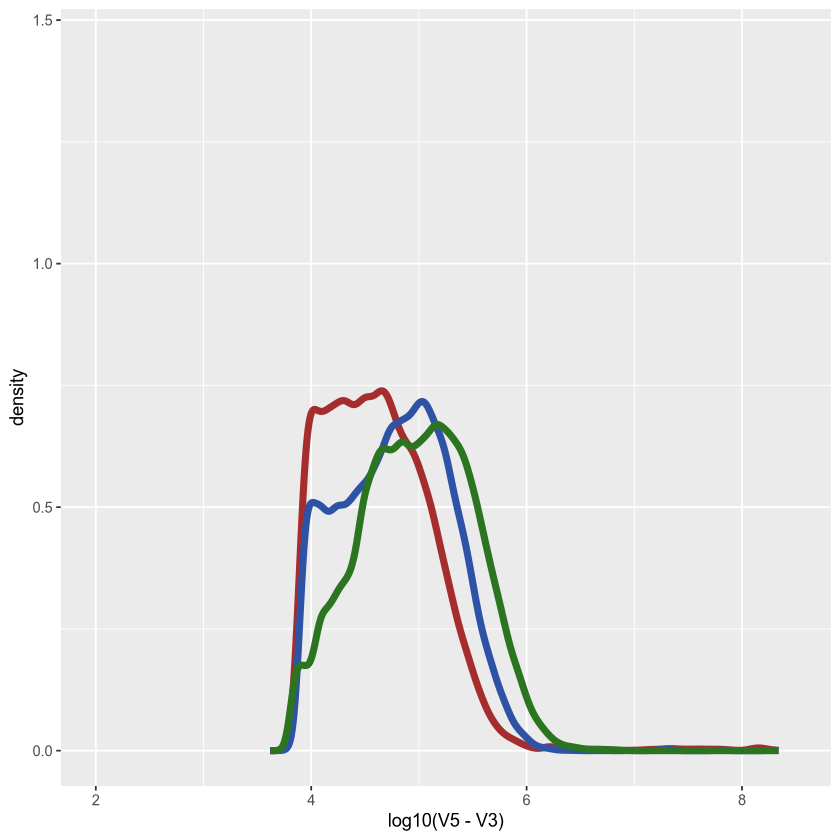

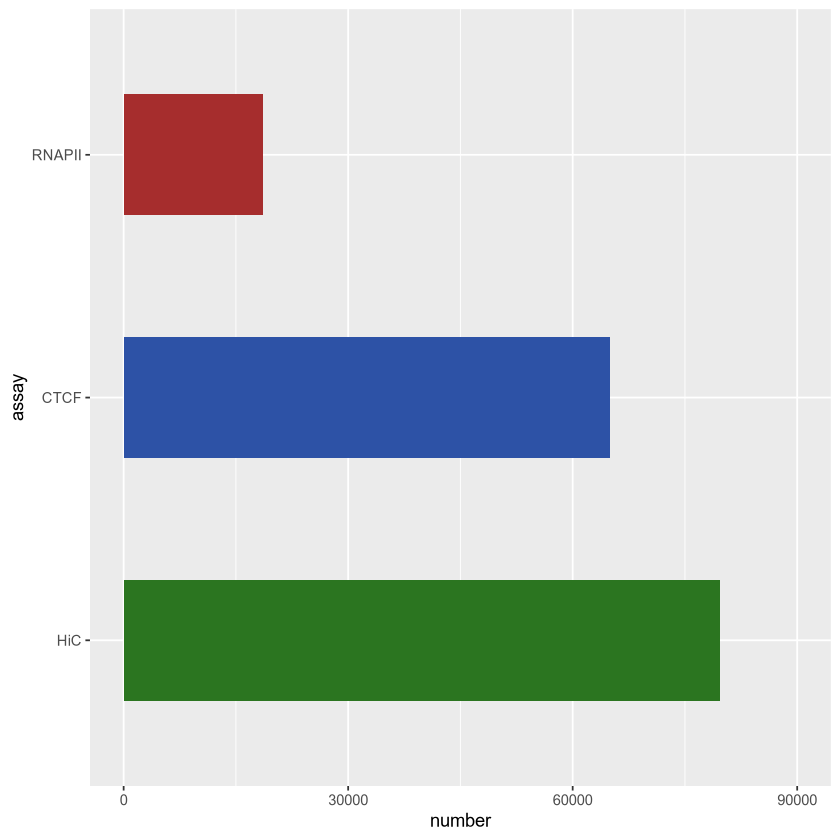

In [74]:
cellType = "Caco-2"
pol2 = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".RNAPII.txt"))
ctcf = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".CTCF.txt"))
hic = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".HiC.txt"))

#pdf(paste0("00_Data//Raw-Figures/Supplemental-Figure-1.",cellType,"-Distribution.pdf"), width=7, height=4.5)
ggplot(pol2, aes(x=log10(V5-V3))) + geom_density(color="#a62d2d", linewidth=2) + 
    geom_density(data=ctcf, aes((x=log10(V5-V3))), color="#2d52a6", linewidth=2) +
    geom_density(data=hic, aes((x=log10(V5-V3))), color="#2b7520", linewidth=2) +
    coord_cartesian(x=c(2,8.5), y=c(0,1.45))
#dev.off()

#pdf(paste0("00_Data//Raw-Figures/Supplemental-Figure-1.",cellType,"-Counts.pdf"), width=5, height=2.5)
counts = data.frame(assay=c("RNAPII","CTCF","HiC"),number=c(dim(pol2)[1], dim(ctcf)[1], dim(hic)[1]))
counts$assay = factor(counts$assay, levels = c("HiC", "CTCF", "RNAPII"))
ggplot(counts, aes(x=number, y=assay)) + 
    geom_bar(stat="identity", fill=c("#a62d2d","#2d52a6","#2b7520"), width=0.5) +
    scale_x_continuous(limits=c(0,90000), breaks=seq(0,90000,30000))
#dev.off()


### HCT116

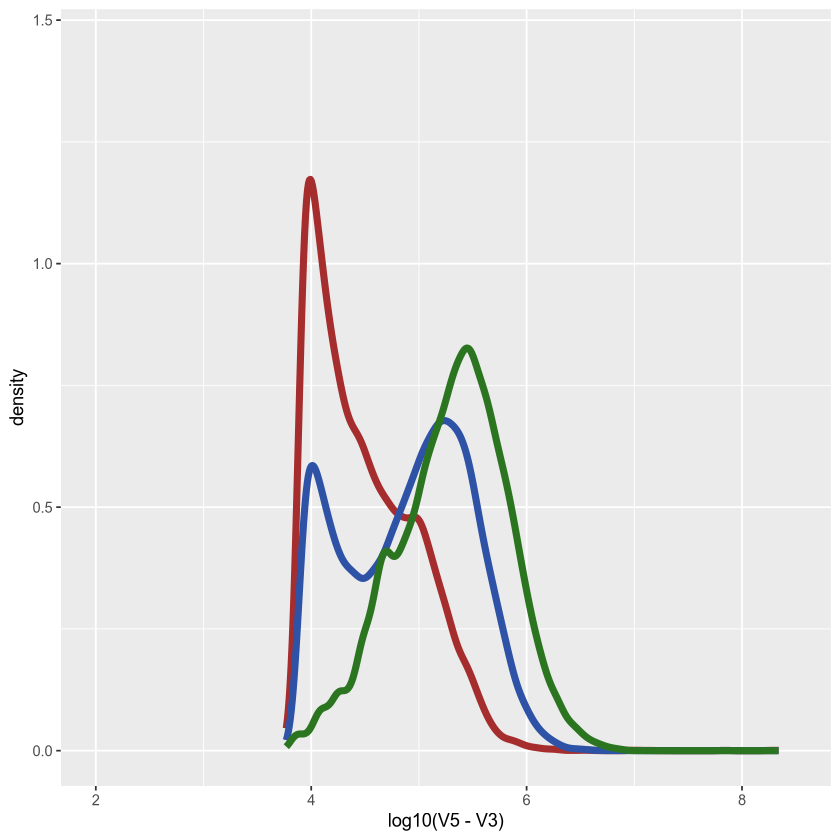

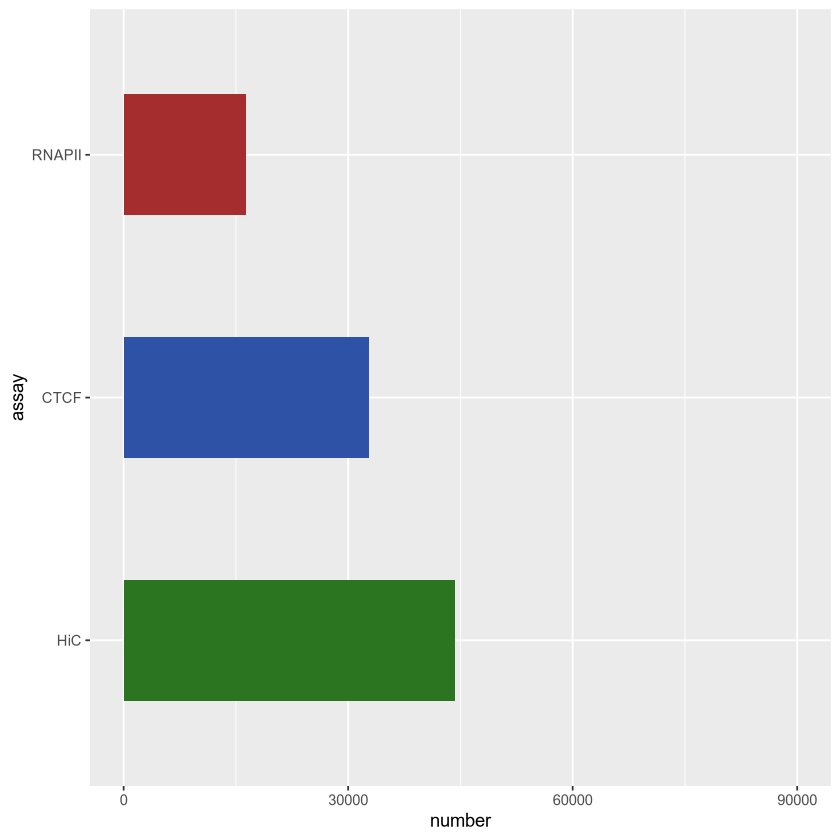

In [75]:
cellType = "HCT116"
pol2 = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".RNAPII.txt"))
ctcf = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".CTCF.txt"))
hic = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".HiC.txt"))

#pdf(paste0("00_Data//Raw-Figures/Supplemental-Figure-1.",cellType,"-Distribution.pdf"), width=7, height=4.5)
ggplot(pol2, aes(x=log10(V5-V3))) + geom_density(color="#a62d2d", linewidth=2) + 
    geom_density(data=ctcf, aes((x=log10(V5-V3))), color="#2d52a6", linewidth=2) +
    geom_density(data=hic, aes((x=log10(V5-V3))), color="#2b7520", linewidth=2) +
    coord_cartesian(x=c(2,8.5), y=c(0,1.45))
#dev.off()

#pdf(paste0("00_Data//Raw-Figures/Supplemental-Figure-1.",cellType,"-Counts.pdf"), width=5, height=2.5)
counts = data.frame(assay=c("RNAPII","CTCF","HiC"),number=c(dim(pol2)[1], dim(ctcf)[1], dim(hic)[1]))
counts$assay = factor(counts$assay, levels = c("HiC", "CTCF", "RNAPII"))
ggplot(counts, aes(x=number, y=assay)) + 
    geom_bar(stat="identity", fill=c("#a62d2d","#2d52a6","#2b7520"), width=0.5) +
    scale_x_continuous(limits=c(0,90000), breaks=seq(0,90000,30000))
#dev.off()


### HepG2

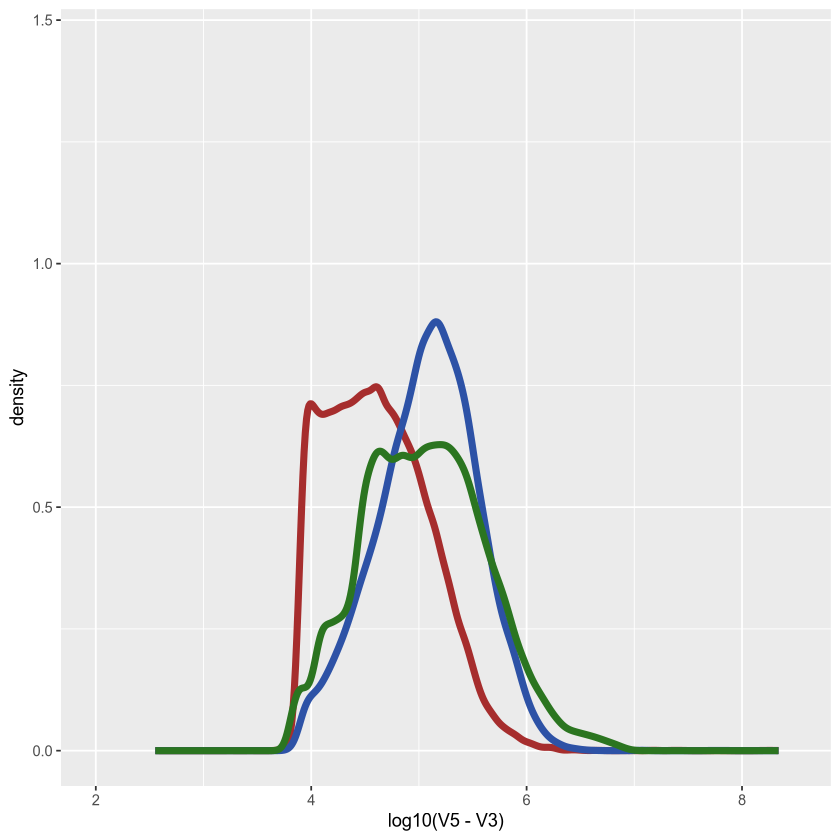

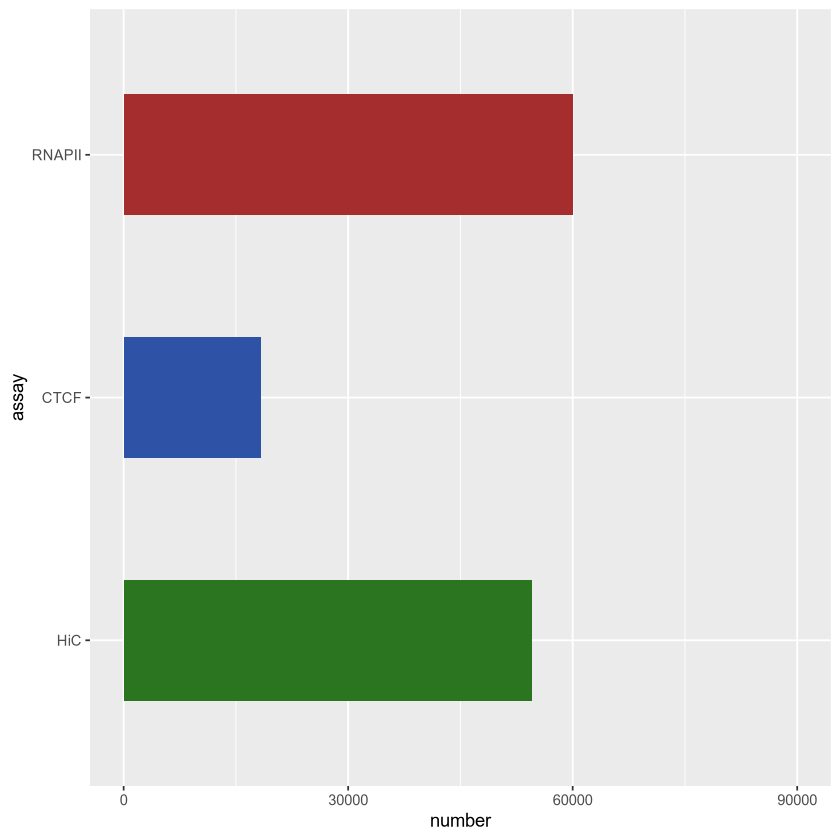

In [76]:
cellType = "HepG2"
pol2 = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".RNAPII.txt"))
ctcf = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".CTCF.txt"))
hic = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".HiC.txt"))

#pdf(paste0("00_Data//Raw-Figures/Supplemental-Figure-1.",cellType,"-Distribution.pdf"), width=7, height=4.5)
ggplot(pol2, aes(x=log10(V5-V3))) + geom_density(color="#a62d2d", linewidth=2) + 
    geom_density(data=ctcf, aes((x=log10(V5-V3))), color="#2d52a6", linewidth=2) +
    geom_density(data=hic, aes((x=log10(V5-V3))), color="#2b7520", linewidth=2) +
    coord_cartesian(x=c(2,8.5), y=c(0,1.45))
#dev.off()

#pdf(paste0("00_Data//Raw-Figures/Supplemental-Figure-1.",cellType,"-Counts.pdf"), width=5, height=2.5)
counts = data.frame(assay=c("RNAPII","CTCF","HiC"),number=c(dim(pol2)[1], dim(ctcf)[1], dim(hic)[1]))
counts$assay = factor(counts$assay, levels = c("HiC", "CTCF", "RNAPII"))
ggplot(counts, aes(x=number, y=assay)) + 
    geom_bar(stat="identity", fill=c("#a62d2d","#2d52a6","#2b7520"), width=0.5) +
    scale_x_continuous(limits=c(0,90000), breaks=seq(0,90000,30000))
#dev.off()

### K562

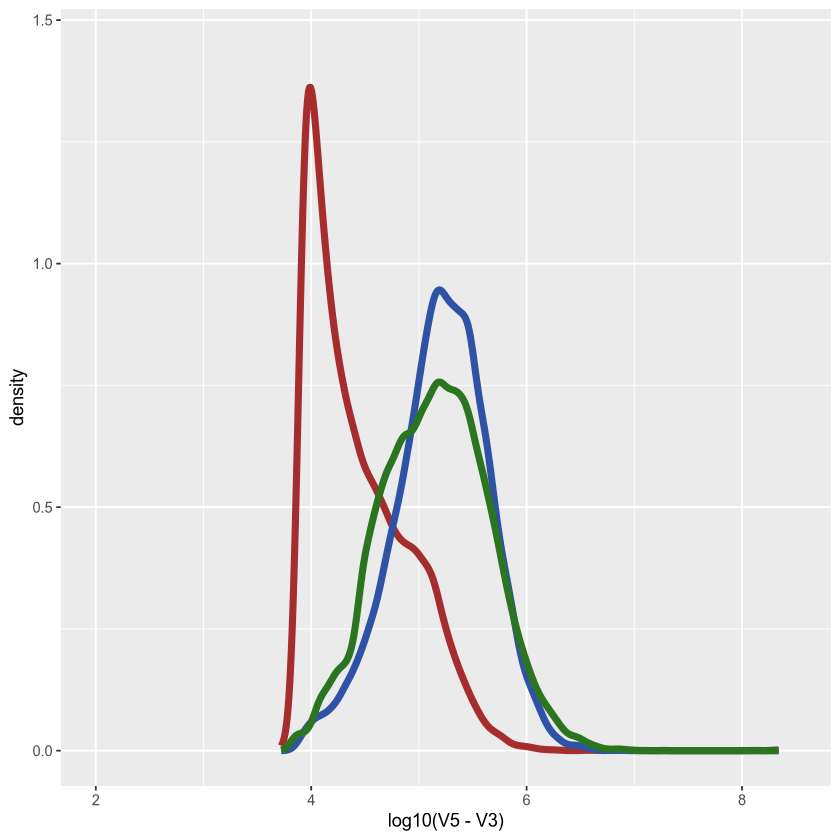

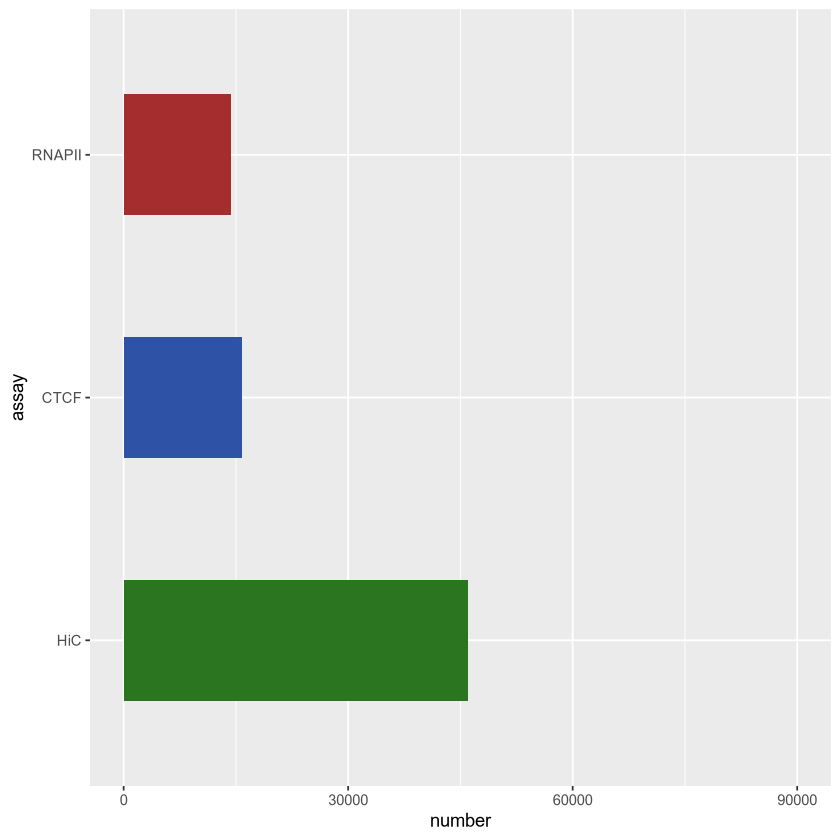

In [77]:
cellType = "K562"
pol2 = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".RNAPII.txt"))
ctcf = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".CTCF.txt"))
hic = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".HiC.txt"))

#pdf(paste0("00_Data//Raw-Figures/Supplemental-Figure-1.",cellType,"-Distribution.pdf"), width=7, height=4.5)
ggplot(pol2, aes(x=log10(V5-V3))) + geom_density(color="#a62d2d", linewidth=2) + 
    geom_density(data=ctcf, aes((x=log10(V5-V3))), color="#2d52a6", linewidth=2) +
    geom_density(data=hic, aes((x=log10(V5-V3))), color="#2b7520", linewidth=2) +
    coord_cartesian(x=c(2,8.5), y=c(0,1.45))
#dev.off()

#pdf(paste0("00_Data//Raw-Figures/Supplemental-Figure-1.",cellType,"-Counts.pdf"), width=5, height=2.5)
counts = data.frame(assay=c("RNAPII","CTCF","HiC"),number=c(dim(pol2)[1], dim(ctcf)[1], dim(hic)[1]))
counts$assay = factor(counts$assay, levels = c("HiC", "CTCF", "RNAPII"))
ggplot(counts, aes(x=number, y=assay)) + 
    geom_bar(stat="identity", fill=c("#a62d2d","#2d52a6","#2b7520"), width=0.5) +
    scale_x_continuous(limits=c(0,90000), breaks=seq(0,90000,30000))
#dev.off()

### MCF-7

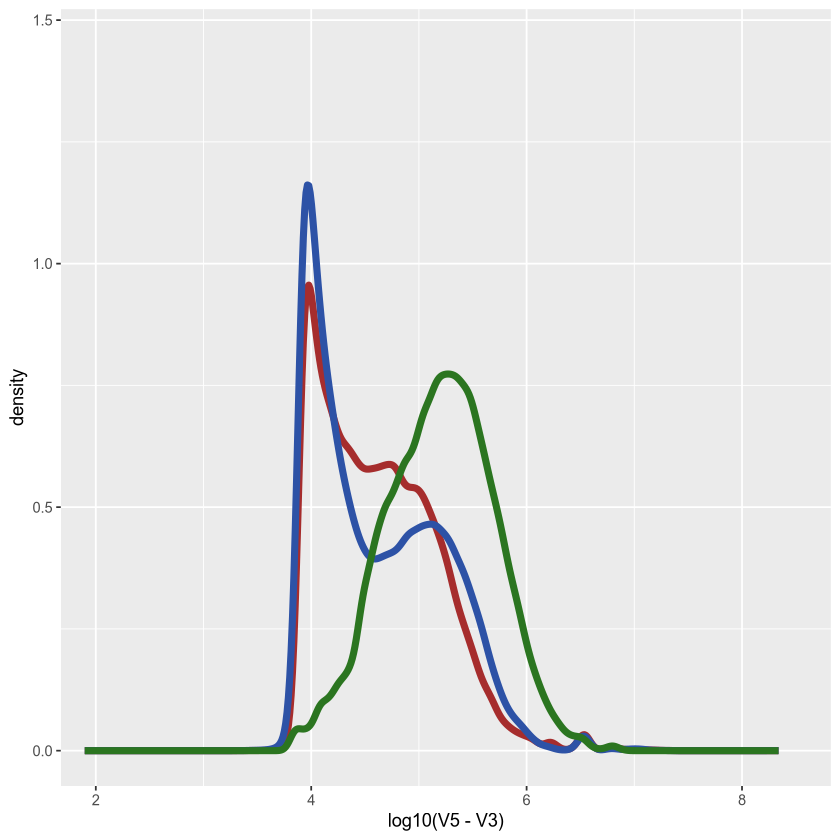

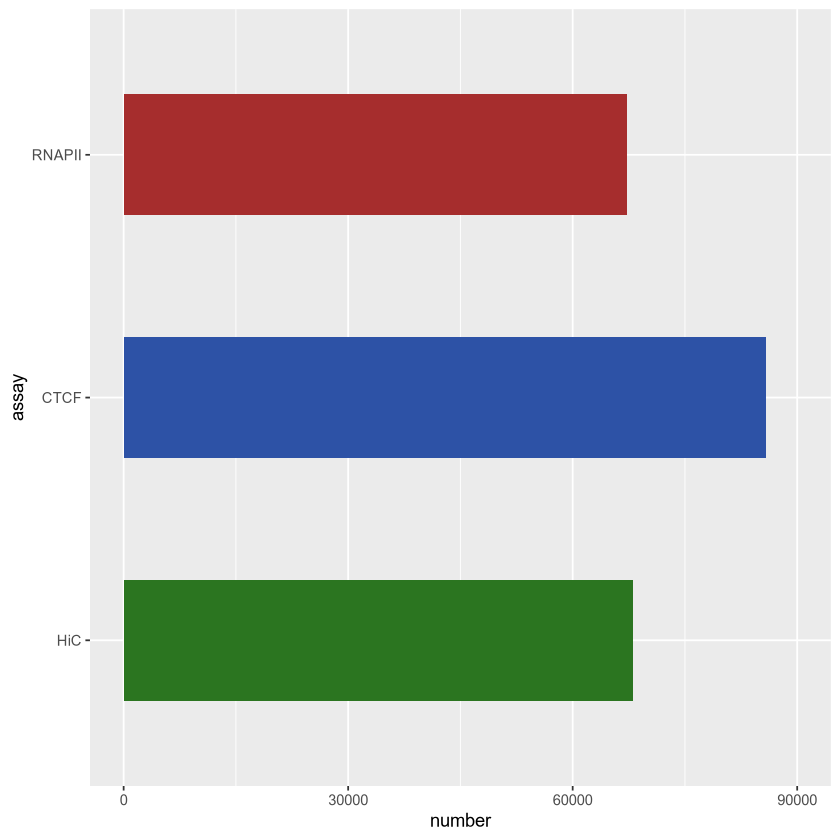

In [78]:
cellType = "MCF-7"
pol2 = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".RNAPII.txt"))
ctcf = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".CTCF.txt"))
hic = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".HiC.txt"))

#pdf(paste0("00_Data//Raw-Figures/Supplemental-Figure-1.",cellType,"-Distribution.pdf"), width=7, height=4.5)
ggplot(pol2, aes(x=log10(V5-V3))) + geom_density(color="#a62d2d", linewidth=2) + 
    geom_density(data=ctcf, aes((x=log10(V5-V3))), color="#2d52a6", linewidth=2) +
    geom_density(data=hic, aes((x=log10(V5-V3))), color="#2b7520", linewidth=2) +
    coord_cartesian(x=c(2,8.5), y=c(0,1.45))
#dev.off()

#pdf(paste0("00_Data//Raw-Figures/Supplemental-Figure-1.",cellType,"-Counts.pdf"), width=5, height=2.5)
counts = data.frame(assay=c("RNAPII","CTCF","HiC"),number=c(dim(pol2)[1], dim(ctcf)[1], dim(hic)[1]))
counts$assay = factor(counts$assay, levels = c("HiC", "CTCF", "RNAPII"))
ggplot(counts, aes(x=number, y=assay)) + 
    geom_bar(stat="identity", fill=c("#a62d2d","#2d52a6","#2b7520"), width=0.5) +
    scale_x_continuous(limits=c(0,90000), breaks=seq(0,90000,30000))
#dev.off()

### MCF 10A

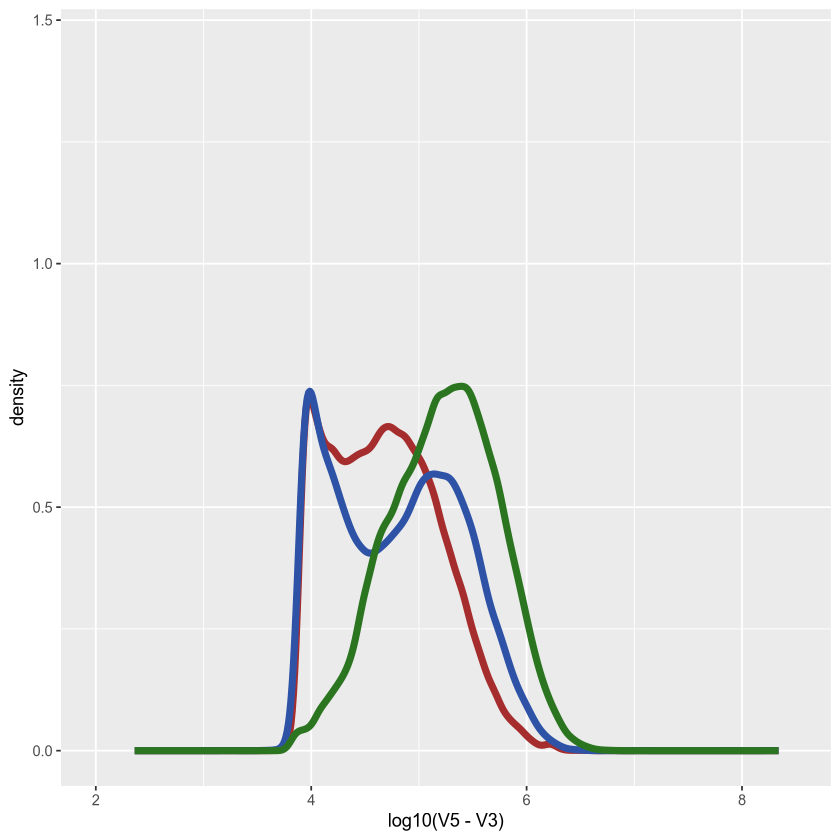

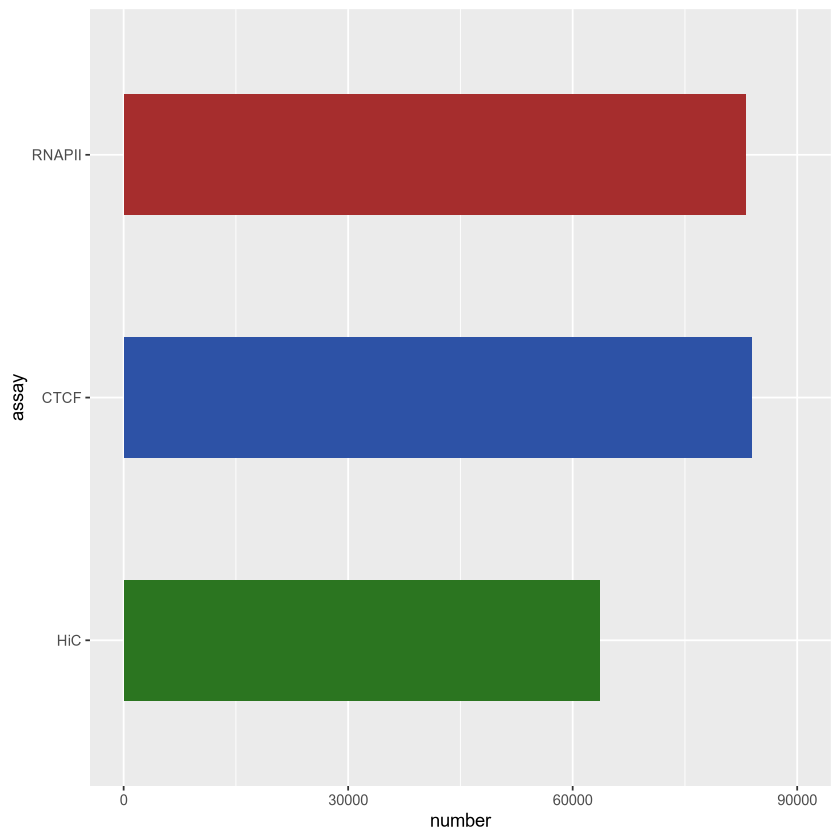

In [79]:
cellType = "MCF"
pol2 = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".RNAPII.txt"))
ctcf = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".CTCF.txt"))
hic = read.table(paste0("00_Data/Supplemental_Datasets/",cellType,".HiC.txt"))

#pdf(paste0("00_Data//Raw-Figures/Supplemental-Figure-1.",cellType,"-Distribution.pdf"), width=7, height=4.5)
ggplot(pol2, aes(x=log10(V5-V3))) + geom_density(color="#a62d2d", linewidth=2) + 
    geom_density(data=ctcf, aes((x=log10(V5-V3))), color="#2d52a6", linewidth=2) +
    geom_density(data=hic, aes((x=log10(V5-V3))), color="#2b7520", linewidth=2) +
    coord_cartesian(x=c(2,8.5), y=c(0,1.45))
#dev.off()

#pdf(paste0("00_Data//Raw-Figures/Supplemental-Figure-1.",cellType,"-Counts.pdf"), width=5, height=2.5)
counts = data.frame(assay=c("RNAPII","CTCF","HiC"),number=c(dim(pol2)[1], dim(ctcf)[1], dim(hic)[1]))
counts$assay = factor(counts$assay, levels = c("HiC", "CTCF", "RNAPII"))
ggplot(counts, aes(x=number, y=assay)) + 
    geom_bar(stat="identity", fill=c("#a62d2d","#2d52a6","#2b7520"), width=0.5) +
    scale_x_continuous(limits=c(0,90000), breaks=seq(0,90000,30000))
#dev.off()

## Supplemental Figure 2

### Distance between anchors of promoter-centric interactions

#### Caco-2

Group.1,x
<chr>,<dbl>
P-C CTCF-Anchors,100000.0
P-C No-CTCF,63000.0
P-E CTCF-Anchors,68396.0
P-E No-CTCF,47578.0
P-P CTCF-Anchors,67700.0
P-P No-CTCF,60575.5



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pp$V5 - pp$V3 and pp$V9 

        CTCF-Anchors
No-CTCF 0.016       

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pe$V5 - pe$V3 and pe$V9 

        CTCF-Anchors
No-CTCF <2e-16      

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pc$V5 - pc$V3 and pc$V9 

        CTCF-Anchors
No-CTCF <2e-16      

P value adjustment method: holm 

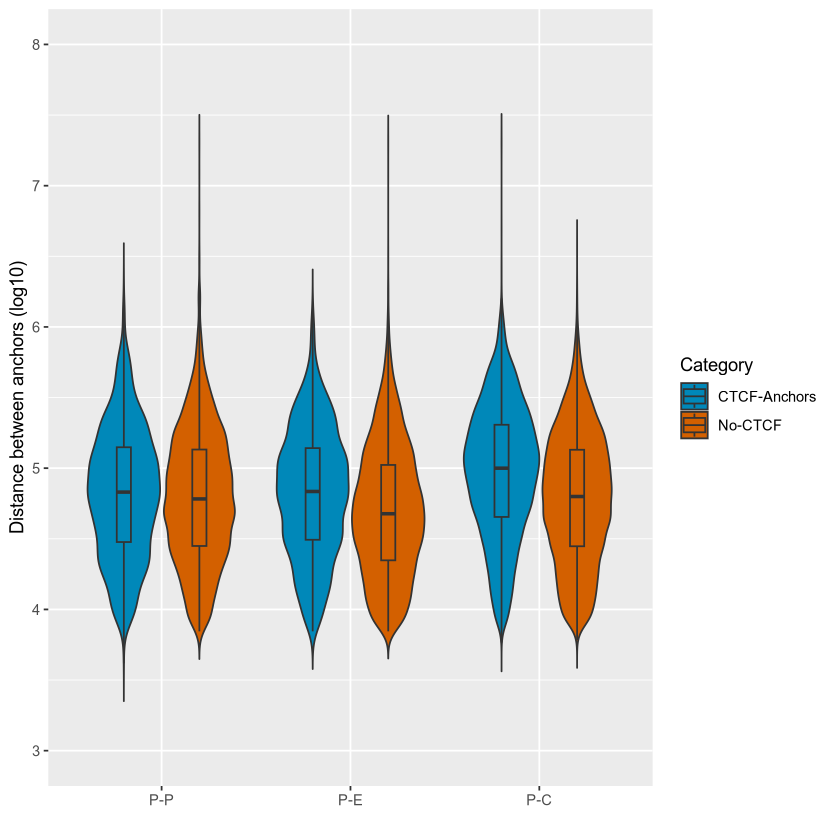

In [41]:
cellType = "Caco-2"

pd = position_dodge(width = 0.8)

d = read.table(paste0("2_Promoter-Centric/Promoter-Centric-Annotations/",cellType,".Promoter-Links.txt"))
d[,8][d[,8] %in% c("P-Ed", "P-Ep")] <- "P-E"

e=d[d$V8 == "P-P" | d$V8 == "P-E" | d$V8 == "P-C",]
e$V8 = factor(e$V8, levels=c("P-P","P-E","P-C"))

#pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-2.",cellType,"-Promoter-Centric-Distance.pdf"), width=6, height=4.5)
ggplot(e, aes(y=log10(V5-V3), x=V8, fill=V9)) +   geom_violin(position = pd, width = 0.8, trim = FALSE) +
    geom_boxplot(position = pd, width = 0.15, outlier.shape = NA) + coord_cartesian(y=c(3,log10(100000000))) +
    xlab("") + ylab("Distance between anchors (log10)") + scale_fill_manual(values=c("#0088b9","#d36000"), name="Category")
#dev.off()

aggregate(e$V5-e$V3, list(paste(e$V8,e$V9)), FUN=median) 

pp = e[e$V8 == "P-P",]
pairwise.wilcox.test(pp$V5-pp$V3, pp$V9)

pe = e[e$V8 == "P-E",]
pairwise.wilcox.test(pe$V5-pe$V3, pe$V9)

pc = e[e$V8 == "P-C",]
pairwise.wilcox.test(pc$V5-pc$V3, pc$V9)

#### HCT116


Group.1,x
<chr>,<dbl>
P-C CTCF-Anchors,162520.5
P-C No-CTCF,87565.0
P-E CTCF-Anchors,82000.0
P-E No-CTCF,46000.0
P-P CTCF-Anchors,75644.0
P-P No-CTCF,55000.0



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pp$V5 - pp$V3 and pp$V9 

        CTCF-Anchors
No-CTCF 2.9e-14     

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pe$V5 - pe$V3 and pe$V9 

        CTCF-Anchors
No-CTCF <2e-16      

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pc$V5 - pc$V3 and pc$V9 

        CTCF-Anchors
No-CTCF <2e-16      

P value adjustment method: holm 

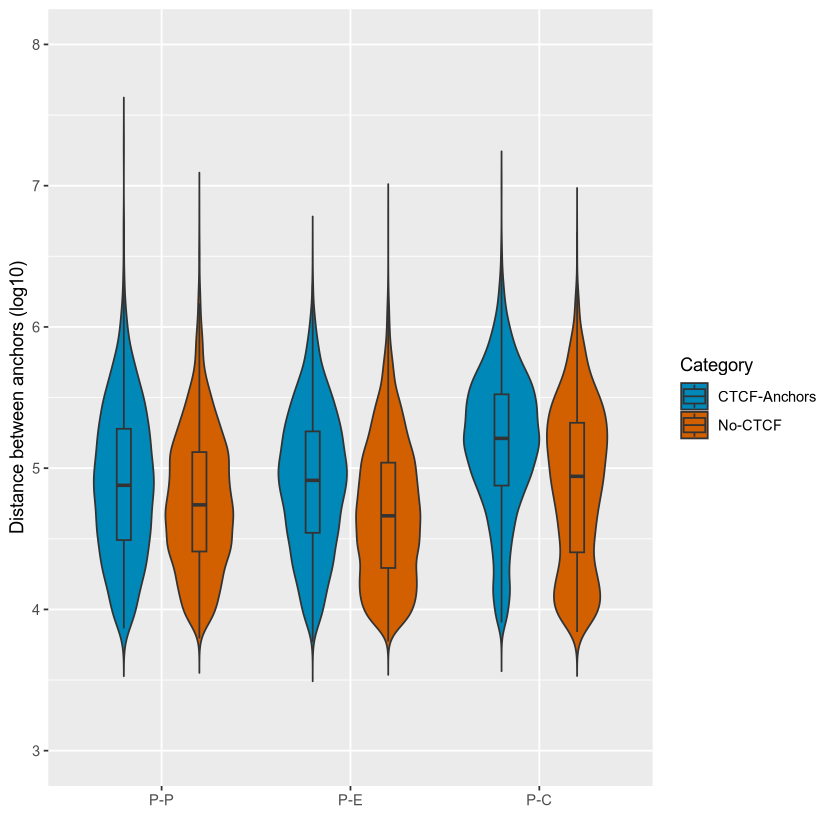

In [44]:
cellType = "HCT116"

pd = position_dodge(width = 0.8)

d = read.table(paste0("2_Promoter-Centric/Promoter-Centric-Annotations/",cellType,".Promoter-Links.txt"))
d[,8][d[,8] %in% c("P-Ed", "P-Ep")] <- "P-E"

e=d[d$V8 == "P-P" | d$V8 == "P-E" | d$V8 == "P-C",]
e$V8 = factor(e$V8, levels=c("P-P","P-E","P-C"))

#pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-2.",cellType,"-Promoter-Centric-Distance.pdf"), width=6, height=4.5)
ggplot(e, aes(y=log10(V5-V3), x=V8, fill=V9)) +   geom_violin(position = pd, width = 0.8, trim = FALSE) +
    geom_boxplot(position = pd, width = 0.15, outlier.shape = NA) + coord_cartesian(y=c(3,log10(100000000))) +
    xlab("") + ylab("Distance between anchors (log10)") + scale_fill_manual(values=c("#0088b9","#d36000"), name="Category")
#dev.off()

aggregate(e$V5-e$V3, list(paste(e$V8,e$V9)), FUN=median) 

pp = e[e$V8 == "P-P",]
pairwise.wilcox.test(pp$V5-pp$V3, pp$V9)

pe = e[e$V8 == "P-E",]
pairwise.wilcox.test(pe$V5-pe$V3, pe$V9)

pc = e[e$V8 == "P-C",]
pairwise.wilcox.test(pc$V5-pc$V3, pc$V9)

#### HepG2

Group.1,x
<chr>,<dbl>
P-C CTCF-Anchors,92792.0
P-C No-CTCF,53809.0
P-E CTCF-Anchors,68000.0
P-E No-CTCF,54517.5
P-P CTCF-Anchors,70000.0
P-P No-CTCF,77603.0



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pp$V5 - pp$V3 and pp$V9 

        CTCF-Anchors
No-CTCF 0.0018      

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pe$V5 - pe$V3 and pe$V9 

        CTCF-Anchors
No-CTCF 1.7e-15     

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pc$V5 - pc$V3 and pc$V9 

        CTCF-Anchors
No-CTCF <2e-16      

P value adjustment method: holm 

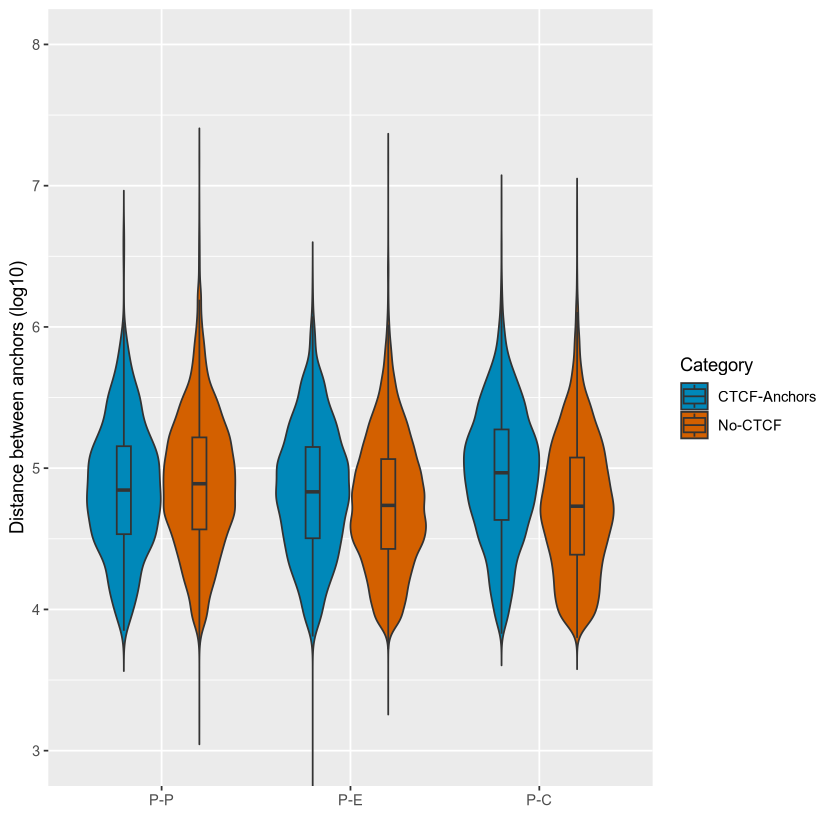

In [45]:
cellType = "HepG2"

pd = position_dodge(width = 0.8)

d = read.table(paste0("2_Promoter-Centric/Promoter-Centric-Annotations/",cellType,".Promoter-Links.txt"))
d[,8][d[,8] %in% c("P-Ed", "P-Ep")] <- "P-E"

e=d[d$V8 == "P-P" | d$V8 == "P-E" | d$V8 == "P-C",]
e$V8 = factor(e$V8, levels=c("P-P","P-E","P-C"))

#pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-2.",cellType,"-Promoter-Centric-Distance.pdf"), width=6, height=4.5)
ggplot(e, aes(y=log10(V5-V3), x=V8, fill=V9)) +   geom_violin(position = pd, width = 0.8, trim = FALSE) +
    geom_boxplot(position = pd, width = 0.15, outlier.shape = NA) + coord_cartesian(y=c(3,log10(100000000))) +
    xlab("") + ylab("Distance between anchors (log10)") + scale_fill_manual(values=c("#0088b9","#d36000"), name="Category")
#dev.off()

aggregate(e$V5-e$V3, list(paste(e$V8,e$V9)), FUN=median) 

pp = e[e$V8 == "P-P",]
pairwise.wilcox.test(pp$V5-pp$V3, pp$V9)

pe = e[e$V8 == "P-E",]
pairwise.wilcox.test(pe$V5-pe$V3, pe$V9)

pc = e[e$V8 == "P-C",]
pairwise.wilcox.test(pc$V5-pc$V3, pc$V9)

#### K562

Group.1,x
<chr>,<dbl>
P-C CTCF-Anchors,129870.0
P-C No-CTCF,94000.0
P-E CTCF-Anchors,77326.0
P-E No-CTCF,50000.0
P-P CTCF-Anchors,79125.5
P-P No-CTCF,70000.0



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pp$V5 - pp$V3 and pp$V9 

        CTCF-Anchors
No-CTCF 0.0023      

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pe$V5 - pe$V3 and pe$V9 

        CTCF-Anchors
No-CTCF <2e-16      

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pc$V5 - pc$V3 and pc$V9 

        CTCF-Anchors
No-CTCF <2e-16      

P value adjustment method: holm 

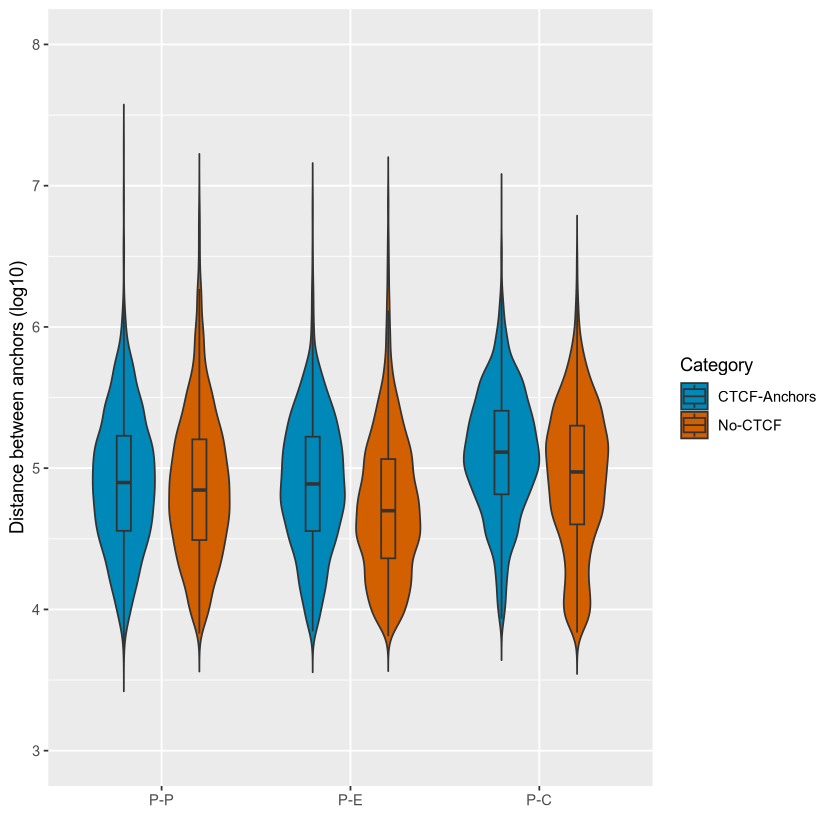

In [46]:
cellType = "K562"

pd = position_dodge(width = 0.8)

d = read.table(paste0("2_Promoter-Centric/Promoter-Centric-Annotations/",cellType,".Promoter-Links.txt"))
d[,8][d[,8] %in% c("P-Ed", "P-Ep")] <- "P-E"

e=d[d$V8 == "P-P" | d$V8 == "P-E" | d$V8 == "P-C",]
e$V8 = factor(e$V8, levels=c("P-P","P-E","P-C"))

#pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-2.",cellType,"-Promoter-Centric-Distance.pdf"), width=6, height=4.5)
ggplot(e, aes(y=log10(V5-V3), x=V8, fill=V9)) +   geom_violin(position = pd, width = 0.8, trim = FALSE) +
    geom_boxplot(position = pd, width = 0.15, outlier.shape = NA) + coord_cartesian(y=c(3,log10(100000000))) +
    xlab("") + ylab("Distance between anchors (log10)") + scale_fill_manual(values=c("#0088b9","#d36000"), name="Category")
#dev.off()

aggregate(e$V5-e$V3, list(paste(e$V8,e$V9)), FUN=median) 

pp = e[e$V8 == "P-P",]
pairwise.wilcox.test(pp$V5-pp$V3, pp$V9)

pe = e[e$V8 == "P-E",]
pairwise.wilcox.test(pe$V5-pe$V3, pe$V9)

pc = e[e$V8 == "P-C",]
pairwise.wilcox.test(pc$V5-pc$V3, pc$V9)

#### MCF 10A

Group.1,x
<chr>,<dbl>
P-C CTCF-Anchors,129398.5
P-C No-CTCF,80000.0
P-E CTCF-Anchors,93365.0
P-E No-CTCF,70763.0
P-P CTCF-Anchors,86070.0
P-P No-CTCF,93300.5



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pp$V5 - pp$V3 and pp$V9 

        CTCF-Anchors
No-CTCF 0.0067      

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pe$V5 - pe$V3 and pe$V9 

        CTCF-Anchors
No-CTCF <2e-16      

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pc$V5 - pc$V3 and pc$V9 

        CTCF-Anchors
No-CTCF <2e-16      

P value adjustment method: holm 

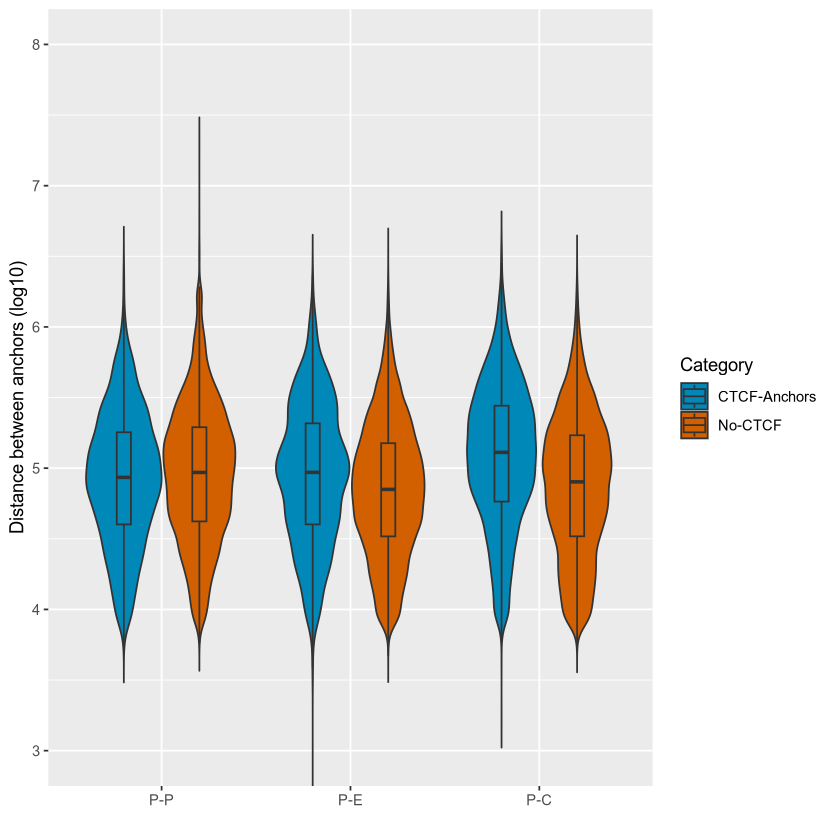

In [43]:
cellType = "MCF"

pd = position_dodge(width = 0.8)

d = read.table(paste0("2_Promoter-Centric/Promoter-Centric-Annotations/",cellType,".Promoter-Links.txt"))
d[,8][d[,8] %in% c("P-Ed", "P-Ep")] <- "P-E"

e=d[d$V8 == "P-P" | d$V8 == "P-E" | d$V8 == "P-C",]
e$V8 = factor(e$V8, levels=c("P-P","P-E","P-C"))

#pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-2.",cellType,"-Promoter-Centric-Distance.pdf"), width=6, height=4.5)
ggplot(e, aes(y=log10(V5-V3), x=V8, fill=V9)) +   geom_violin(position = pd, width = 0.8, trim = FALSE) +
    geom_boxplot(position = pd, width = 0.15, outlier.shape = NA) + coord_cartesian(y=c(3,log10(100000000))) +
    xlab("") + ylab("Distance between anchors (log10)") + scale_fill_manual(values=c("#0088b9","#d36000"), name="Category")
#dev.off()

aggregate(e$V5-e$V3, list(paste(e$V8,e$V9)), FUN=median) 

pp = e[e$V8 == "P-P",]
pairwise.wilcox.test(pp$V5-pp$V3, pp$V9)

pe = e[e$V8 == "P-E",]
pairwise.wilcox.test(pe$V5-pe$V3, pe$V9)

pc = e[e$V8 == "P-C",]
pairwise.wilcox.test(pc$V5-pc$V3, pc$V9)

#### MCF-7

Group.1,x
<chr>,<dbl>
P-C CTCF-Anchors,106000.0
P-C No-CTCF,66000.0
P-E CTCF-Anchors,65566.5
P-E No-CTCF,52432.0
P-P CTCF-Anchors,67859.5
P-P No-CTCF,64135.0



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pp$V5 - pp$V3 and pp$V9 

        CTCF-Anchors
No-CTCF 0.29        

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pe$V5 - pe$V3 and pe$V9 

        CTCF-Anchors
No-CTCF <2e-16      

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  pc$V5 - pc$V3 and pc$V9 

        CTCF-Anchors
No-CTCF <2e-16      

P value adjustment method: holm 

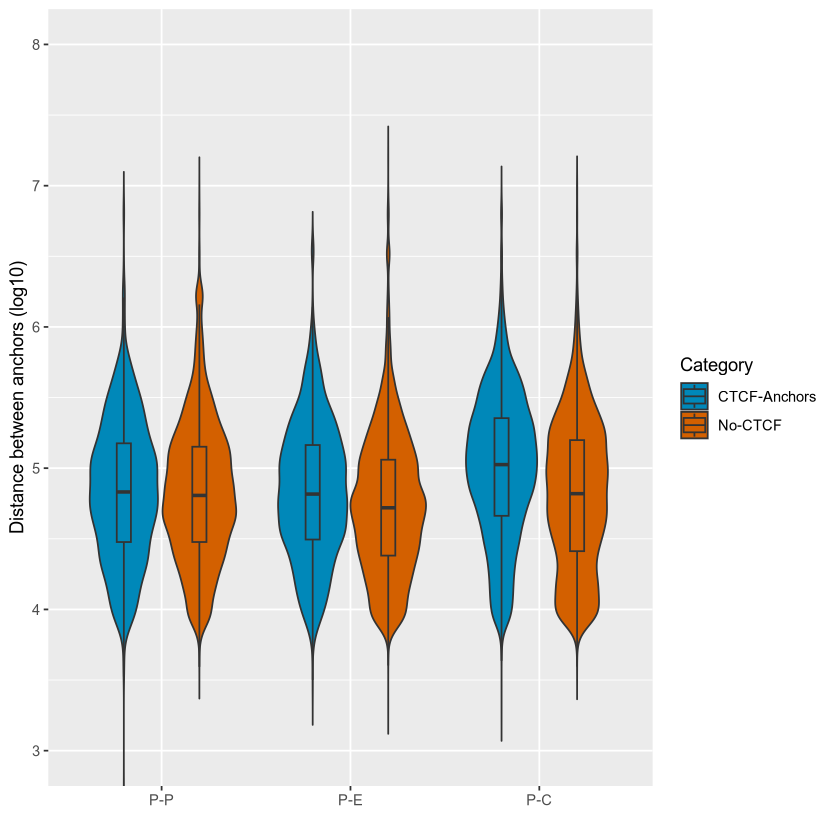

In [42]:
cellType = "MCF-7"

pd = position_dodge(width = 0.8)

d = read.table(paste0("2_Promoter-Centric/Promoter-Centric-Annotations/",cellType,".Promoter-Links.txt"))
d[,8][d[,8] %in% c("P-Ed", "P-Ep")] <- "P-E"

e=d[d$V8 == "P-P" | d$V8 == "P-E" | d$V8 == "P-C",]
e$V8 = factor(e$V8, levels=c("P-P","P-E","P-C"))

#pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-2.",cellType,"-Promoter-Centric-Distance.pdf"), width=6, height=4.5)
ggplot(e, aes(y=log10(V5-V3), x=V8, fill=V9)) +   geom_violin(position = pd, width = 0.8, trim = FALSE) +
    geom_boxplot(position = pd, width = 0.15, outlier.shape = NA) + coord_cartesian(y=c(3,log10(100000000))) +
    xlab("") + ylab("Distance between anchors (log10)") + scale_fill_manual(values=c("#0088b9","#d36000"), name="Category")
#dev.off()

aggregate(e$V5-e$V3, list(paste(e$V8,e$V9)), FUN=median) 

pp = e[e$V8 == "P-P",]
pairwise.wilcox.test(pp$V5-pp$V3, pp$V9)

pe = e[e$V8 == "P-E",]
pairwise.wilcox.test(pe$V5-pe$V3, pe$V9)

pc = e[e$V8 == "P-C",]
pairwise.wilcox.test(pc$V5-pc$V3, pc$V9)

## Supplemental Figure 3

### Gene expression

#### Caco-2

In [59]:
cellType = "Caco-2"

pd = position_dodge(width = 0.8)

d = read.table(paste0("2_Promoter-Centric/Expression/",cellType,".Expression.txt"))
d$V3 = factor(d$V3, levels=c("P-P","P-E-C","None"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-3.",cellType,"-Promoter-Centric-Expression.pdf"), width=6, height=4.5)
ggplot(d, aes(x=V3, y=log10(V2+0.01))) + geom_violin() + geom_boxplot(width=0.1) + 
    coord_cartesian(y=c(-2,6)) + ylab("Log10 TPM") + xlab("")
dev.off()

aggregate(d$V2, list(d$V3), FUN=median) 
pairwise.wilcox.test(d$V2, d$V3, p.adj="fdr")

pdf 
  2

Group.1,x
<fct>,<dbl>
P-P,11.4200
P-E-C,7.7100
None,5.1275



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V2 and d$V3 

      P-P     P-E-C  
P-E-C < 2e-16 -      
None  < 2e-16 1.9e-08

P value adjustment method: fdr 

#### HCT116

In [60]:
cellType = "HCT116"

pd = position_dodge(width = 0.8)

d = read.table(paste0("2_Promoter-Centric/Expression/",cellType,".Expression.txt"))
d$V3 = factor(d$V3, levels=c("P-P","P-E-C","None"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-3.",cellType,"-Promoter-Centric-Expression.pdf"), width=6, height=4.5)
ggplot(d, aes(x=V3, y=log10(V2+0.01))) + geom_violin() + geom_boxplot(width=0.1) + 
    coord_cartesian(y=c(-2,6)) + ylab("Log10 TPM") + xlab("")
dev.off()

aggregate(d$V2, list(d$V3), FUN=median) 
pairwise.wilcox.test(d$V2, d$V3, p.adj="fdr")

pdf 
  2

Group.1,x
<fct>,<dbl>
P-P,10.020
P-E-C,7.470
None,6.065



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V2 and d$V3 

      P-P     P-E-C  
P-E-C 2.2e-15 -      
None  < 2e-16 4.0e-07

P value adjustment method: fdr 

#### HepG2

In [61]:
cellType = "HepG2"

pd = position_dodge(width = 0.8)

d = read.table(paste0("2_Promoter-Centric/Expression/",cellType,".Expression.txt"))
d$V3 = factor(d$V3, levels=c("P-P","P-E-C","None"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-3.",cellType,"-Promoter-Centric-Expression.pdf"), width=6, height=4.5)
ggplot(d, aes(x=V3, y=log10(V2+0.01))) + geom_violin() + geom_boxplot(width=0.1) + 
    coord_cartesian(y=c(-2,6)) + ylab("Log10 TPM") + xlab("")
dev.off()

aggregate(d$V2, list(d$V3), FUN=median) 
pairwise.wilcox.test(d$V2, d$V3, p.adj="fdr")

pdf 
  2

Group.1,x
<fct>,<dbl>
P-P,8.730
P-E-C,6.690
None,3.145



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V2 and d$V3 

      P-P     P-E-C  
P-E-C 7.9e-11 -      
None  < 2e-16 < 2e-16

P value adjustment method: fdr 

#### K562

In [62]:
cellType = "K562"

pd = position_dodge(width = 0.8)

d = read.table(paste0("2_Promoter-Centric/Expression/",cellType,".Expression.txt"))
d$V3 = factor(d$V3, levels=c("P-P","P-E-C","None"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-3.",cellType,"-Promoter-Centric-Expression.pdf"), width=6, height=4.5)
ggplot(d, aes(x=V3, y=log10(V2+0.01))) + geom_violin() + geom_boxplot(width=0.1) + 
    coord_cartesian(y=c(-2,6)) + ylab("Log10 TPM") + xlab("")
dev.off()

aggregate(d$V2, list(d$V3), FUN=median) 
pairwise.wilcox.test(d$V2, d$V3, p.adj="fdr")

pdf 
  2

Group.1,x
<fct>,<dbl>
P-P,10.615
P-E-C,6.535
None,3.225



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V2 and d$V3 

      P-P    P-E-C 
P-E-C <2e-16 -     
None  <2e-16 <2e-16

P value adjustment method: fdr 

#### MCF 10A

In [63]:
cellType = "MCF"

pd = position_dodge(width = 0.8)

d = read.table(paste0("2_Promoter-Centric/Expression/",cellType,".Expression.txt"))
d$V3 = factor(d$V3, levels=c("P-P","P-E-C","None"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-3.",cellType,"-Promoter-Centric-Expression.pdf"), width=6, height=4.5)
ggplot(d, aes(x=V3, y=log10(V2+0.01))) + geom_violin() + geom_boxplot(width=0.1) + 
    coord_cartesian(y=c(-2,6)) + ylab("Log10 TPM") + xlab("")
dev.off()

aggregate(d$V2, list(d$V3), FUN=median) 
pairwise.wilcox.test(d$V2, d$V3, p.adj="fdr")

pdf 
  2

Group.1,x
<fct>,<dbl>
P-P,10.045
P-E-C,5.230
None,3.295



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V2 and d$V3 

      P-P     P-E-C  
P-E-C < 2e-16 -      
None  < 2e-16 5.1e-08

P value adjustment method: fdr 

#### MCF-7

In [64]:
cellType = "MCF-7"

pd = position_dodge(width = 0.8)

d = read.table(paste0("2_Promoter-Centric/Expression/",cellType,".Expression.txt"))
d$V3 = factor(d$V3, levels=c("P-P","P-E-C","None"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-3.",cellType,"-Promoter-Centric-Expression.pdf"), width=6, height=4.5)
ggplot(d, aes(x=V3, y=log10(V2+0.01))) + geom_violin() + geom_boxplot(width=0.1) + 
    coord_cartesian(y=c(-2,6)) + ylab("Log10 TPM") + xlab("")
dev.off()

aggregate(d$V2, list(d$V3), FUN=median) 
pairwise.wilcox.test(d$V2, d$V3, p.adj="fdr")

pdf 
  2

Group.1,x
<fct>,<dbl>
P-P,8.470
P-E-C,3.985
None,1.660



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V2 and d$V3 

      P-P    P-E-C 
P-E-C <2e-16 -     
None  <2e-16 <2e-16

P value adjustment method: fdr 

## Supplemental Figure 5

#### Caco-2

In [45]:
cellType = "Caco-2"

d = read.table(paste0("2_Promoter-Centric/Closest-Gene-Evaluation/",cellType,".Distance-Histogram.txt"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-5.",cellType,"-Distance-Histogram.pdf"), width=7, height=4.5)
ggplot(d, aes(x=log10(V3), fill=V4, y = after_stat(density))) + 
    geom_histogram(binwidth=0.1,color="black",alpha=0.5, position="identity") + 
    geom_vline(xintercept=log10(10000), linetype="dashed") + 
    scale_fill_manual(name="Group",values=c("#1a8a3f", "gray40")) + 
    coord_cartesian(x=c(3,6), y=c(0,1.25)) + 
    xlab("Distance between anchors") + ylab("Density")
dev.off()

pdf 
  2

#### HCT116

In [46]:
cellType = "HCT116"

d = read.table(paste0("2_Promoter-Centric/Closest-Gene-Evaluation/",cellType,".Distance-Histogram.txt"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-5.",cellType,"-Distance-Histogram.pdf"), width=7, height=4.5)
ggplot(d, aes(x=log10(V3), fill=V4, y = after_stat(density))) + 
    geom_histogram(binwidth=0.1,color="black",alpha=0.5, position="identity") + 
    geom_vline(xintercept=log10(10000), linetype="dashed") + 
    scale_fill_manual(name="Group",values=c("#1a8a3f", "gray40")) + 
    coord_cartesian(x=c(3,6), y=c(0,1.25)) + 
    xlab("Distance between anchors") + ylab("Density")
dev.off()

pdf 
  2

#### HepG2

In [47]:
cellType = "HepG2"

d = read.table(paste0("2_Promoter-Centric/Closest-Gene-Evaluation/",cellType,".Distance-Histogram.txt"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-5.",cellType,"-Distance-Histogram.pdf"), width=7, height=4.5)
ggplot(d, aes(x=log10(V3), fill=V4, y = after_stat(density))) + 
    geom_histogram(binwidth=0.1,color="black",alpha=0.5, position="identity") + 
    geom_vline(xintercept=log10(10000), linetype="dashed") + 
    scale_fill_manual(name="Group",values=c("#1a8a3f", "gray40")) + 
    coord_cartesian(x=c(3,6), y=c(0,1.25)) + 
    xlab("Distance between anchors") + ylab("Density")
dev.off()

pdf 
  2

#### K562

In [48]:
cellType = "K562"

d = read.table(paste0("2_Promoter-Centric/Closest-Gene-Evaluation/",cellType,".Distance-Histogram.txt"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-5.",cellType,"-Distance-Histogram.pdf"), width=7, height=4.5)
ggplot(d, aes(x=log10(V3), fill=V4, y = after_stat(density))) + 
    geom_histogram(binwidth=0.1,color="black",alpha=0.5, position="identity") + 
    geom_vline(xintercept=log10(10000), linetype="dashed") + 
    scale_fill_manual(name="Group",values=c("#1a8a3f", "gray40")) + 
    coord_cartesian(x=c(3,6), y=c(0,1.25)) + 
    xlab("Distance between anchors") + ylab("Density")
dev.off()

pdf 
  2

#### MCF 10A

In [49]:
cellType = "MCF"

d = read.table(paste0("2_Promoter-Centric/Closest-Gene-Evaluation/",cellType,".Distance-Histogram.txt"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-5.",cellType,"-Distance-Histogram.pdf"), width=7, height=4.5)
ggplot(d, aes(x=log10(V3), fill=V4, y = after_stat(density))) + 
    geom_histogram(binwidth=0.1,color="black",alpha=0.5, position="identity") + 
    geom_vline(xintercept=log10(10000), linetype="dashed") + 
    scale_fill_manual(name="Group",values=c("#1a8a3f", "gray40")) + 
    coord_cartesian(x=c(3,6), y=c(0,1.25)) + 
    xlab("Distance between anchors") + ylab("Density")
dev.off()

pdf 
  2

#### MCF-7

In [50]:
cellType = "MCF-7"

d = read.table(paste0("2_Promoter-Centric/Closest-Gene-Evaluation/",cellType,".Distance-Histogram.txt"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-5.",cellType,"-Distance-Histogram.pdf"), width=7, height=4.5)
ggplot(d, aes(x=log10(V3), fill=V4, y = after_stat(density))) + 
    geom_histogram(binwidth=0.1,color="black",alpha=0.5, position="identity") + 
    geom_vline(xintercept=log10(10000), linetype="dashed") + 
    scale_fill_manual(name="Group",values=c("#1a8a3f", "gray40")) + 
    coord_cartesian(x=c(3,6), y=c(0,1.25)) + 
    xlab("Distance between anchors") + ylab("Density")
dev.off()

pdf 
  2

## Supplemental Figure 6

#### Caco-2

In [111]:
cellType = "Caco-2"

d = read.table(paste0("2_Promoter-Centric/Gene-Counts/",cellType,".PE-PC-Gene-Counts.txt"))
d$V4 = factor(d$V4, levels=c("P-E","P-C"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-6.",cellType,"-Number-Linked-Genes.pdf"), width=10, height=4.5)
ggplot(d, aes(x=V2, fill=V3, y = after_stat(density))) + geom_histogram(color="black",alpha=0.5, position="identity",binwidth=1) + 
    coord_cartesian(x=c(1,15), y=c(0,0.7)) + ylab("Density") + xlab("# of genes") + 
    scale_fill_manual(values=c("#0088b9","#d36000")) + facet_wrap(~V4)
dev.off()

aggregate(d$V2, list(paste0(d$V3,d$V4)), FUN=mean) 
pairwise.wilcox.test(d$V2, paste0(d$V3,d$V4), p.adj="fdr")

pdf 
  2

Group.1,x
<chr>,<dbl>
archP-C,2.211348
archP-E,3.409266
noarchP-C,1.574480
noarchP-E,1.921817



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V2 and paste0(d$V3, d$V4) 

          archP-C archP-E noarchP-C
archP-E   <2e-16  -       -        
noarchP-C <2e-16  <2e-16  -        
noarchP-E <2e-16  <2e-16  <2e-16   

P value adjustment method: fdr 

#### HCT116

In [104]:
cellType = "HCT116"

d = read.table(paste0("2_Promoter-Centric/Gene-Counts/",cellType,".PE-PC-Gene-Counts.txt"))
d$V4 = factor(d$V4, levels=c("P-E","P-C"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-6.",cellType,"-Number-Linked-Genes.pdf"), width=10, height=4.5)
ggplot(d, aes(x=V2, fill=V3, y = after_stat(density))) + geom_histogram(color="black",alpha=0.5, position="identity",binwidth=1) + 
    coord_cartesian(x=c(1,15), y=c(0,0.7)) + ylab("Density") + xlab("# of genes") + 
    scale_fill_manual(values=c("#0088b9","#d36000")) + facet_wrap(~V4)
dev.off()

aggregate(d$V2, list(paste0(d$V3,d$V4)), FUN=mean) 
pairwise.wilcox.test(d$V2, paste0(d$V3,d$V4), p.adj="fdr")

pdf 
  2

Group.1,x
<chr>,<dbl>
archP-C,1.661692
archP-E,2.317637
noarchP-C,1.468543
noarchP-E,1.706284



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V2 and paste0(d$V3, d$V4) 

          archP-C archP-E noarchP-C
archP-E   < 2e-16 -       -        
noarchP-C 9.4e-09 < 2e-16 -        
noarchP-E 0.00019 < 2e-16 < 2e-16  

P value adjustment method: fdr 

#### HepG2

In [105]:
cellType = "HepG2"

d = read.table(paste0("2_Promoter-Centric/Gene-Counts/",cellType,".PE-PC-Gene-Counts.txt"))
d$V4 = factor(d$V4, levels=c("P-E","P-C"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-6.",cellType,"-Number-Linked-Genes.pdf"), width=10, height=4.5)
ggplot(d, aes(x=V2, fill=V3, y = after_stat(density))) + geom_histogram(color="black",alpha=0.5, position="identity",binwidth=1) + 
    coord_cartesian(x=c(1,15), y=c(0,0.7)) + ylab("Density") + xlab("# of genes") + 
    scale_fill_manual(values=c("#0088b9","#d36000")) + facet_wrap(~V4)
dev.off()

aggregate(d$V2, list(paste0(d$V3,d$V4)), FUN=mean) 
pairwise.wilcox.test(d$V2, paste0(d$V3,d$V4), p.adj="fdr")

pdf 
  2

Group.1,x
<chr>,<dbl>
archP-C,1.911638
archP-E,3.318182
noarchP-C,1.598063
noarchP-E,2.147880



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V2 and paste0(d$V3, d$V4) 

          archP-C archP-E noarchP-C
archP-E   <2e-16  -       -        
noarchP-C <2e-16  <2e-16  -        
noarchP-E <2e-16  <2e-16  <2e-16   

P value adjustment method: fdr 

#### K562

In [106]:
cellType = "K562"

d = read.table(paste0("2_Promoter-Centric/Gene-Counts/",cellType,".PE-PC-Gene-Counts.txt"))
d$V4 = factor(d$V4, levels=c("P-E","P-C"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-6.",cellType,"-Number-Linked-Genes.pdf"), width=10, height=4.5)
ggplot(d, aes(x=V2, fill=V3, y = after_stat(density))) + geom_histogram(color="black",alpha=0.5, position="identity",binwidth=1) + 
    coord_cartesian(x=c(1,15), y=c(0,0.7)) + ylab("Density") + xlab("# of genes") + 
    scale_fill_manual(values=c("#0088b9","#d36000")) + facet_wrap(~V4)
dev.off()

aggregate(d$V2, list(paste0(d$V3,d$V4)), FUN=mean) 
pairwise.wilcox.test(d$V2, paste0(d$V3,d$V4), p.adj="fdr")

pdf 
  2

Group.1,x
<chr>,<dbl>
archP-C,1.672396
archP-E,2.251163
noarchP-C,1.508329
noarchP-E,1.723119



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V2 and paste0(d$V3, d$V4) 

          archP-C archP-E noarchP-C
archP-E   < 2e-16 -       -        
noarchP-C 0.00034 < 2e-16 -        
noarchP-E 0.00075 < 2e-16 1.9e-10  

P value adjustment method: fdr 

#### MCF 10A



In [107]:
cellType = "MCF"

d = read.table(paste0("2_Promoter-Centric/Gene-Counts/",cellType,".PE-PC-Gene-Counts.txt"))
d$V4 = factor(d$V4, levels=c("P-E","P-C"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-6.",cellType,"-Number-Linked-Genes.pdf"), width=10, height=4.5)
ggplot(d, aes(x=V2, fill=V3, y = after_stat(density))) + geom_histogram(color="black",alpha=0.5, position="identity",binwidth=1) + 
    coord_cartesian(x=c(1,15), y=c(0,0.7)) + ylab("Density") + xlab("# of genes") + 
    scale_fill_manual(values=c("#0088b9","#d36000")) + facet_wrap(~V4)
dev.off()

aggregate(d$V2, list(paste0(d$V3,d$V4)), FUN=mean) 
pairwise.wilcox.test(d$V2, paste0(d$V3,d$V4), p.adj="fdr")

pdf 
  2

Group.1,x
<chr>,<dbl>
archP-C,2.181211
archP-E,3.355356
noarchP-C,1.677283
noarchP-E,2.110533



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V2 and paste0(d$V3, d$V4) 

          archP-C archP-E noarchP-C
archP-E   < 2e-16 -       -        
noarchP-C < 2e-16 < 2e-16 -        
noarchP-E 3.3e-05 < 2e-16 < 2e-16  

P value adjustment method: fdr 

#### MCF-7



In [108]:
cellType = "MCF-7"

d = read.table(paste0("2_Promoter-Centric/Gene-Counts/",cellType,".PE-PC-Gene-Counts.txt"))
d$V4 = factor(d$V4, levels=c("P-E","P-C"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-6.",cellType,"-Number-Linked-Genes.pdf"), width=10, height=4.5)
ggplot(d, aes(x=V2, fill=V3, y = after_stat(density))) + geom_histogram(color="black",alpha=0.5, position="identity",binwidth=1) + 
    coord_cartesian(x=c(1,15), y=c(0,0.7)) + ylab("Density") + xlab("# of genes") + 
    scale_fill_manual(values=c("#0088b9","#d36000")) + facet_wrap(~V4)
dev.off()

aggregate(d$V2, list(paste0(d$V3,d$V4)), FUN=mean) 
pairwise.wilcox.test(d$V2, paste0(d$V3,d$V4), p.adj="fdr")

pdf 
  2

Group.1,x
<chr>,<dbl>
archP-C,1.932314
archP-E,2.691188
noarchP-C,1.548182
noarchP-E,1.934584



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V2 and paste0(d$V3, d$V4) 

          archP-C archP-E noarchP-C
archP-E   <2e-16  -       -        
noarchP-C <2e-16  <2e-16  -        
noarchP-E 0.37    <2e-16  <2e-16   

P value adjustment method: fdr 

## Supplemental Figure 7

### Caco-2

In [134]:
cellType = "Caco-2"

d = read.table(paste0("3_Dual-Elements/ChromBPNet/Attribution-Calculations/",cellType,"-ChromBPNet-EC-Attributions.txt"))
#d$V4 = factor(d$V4, levels=c("enha","P-C"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-7.",cellType,"-ChromBPNet-Attribution-Base.pdf"), width=6, height=3)
ggplot(d, aes(x=V7, y=V9, fill=V9)) + geom_boxplot(width = 0.25) + coord_cartesian(x=c(0,200)) + 
    ylab("") + xlab("# high contribution bases") + scale_fill_manual(values=c("#00b0f0","#ffcd00"))
dev.off()

aggregate(d$V7, list(d$V9), FUN=median) 
pairwise.wilcox.test(d$V7, d$V9, p.adj="fdr")


pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-7.",cellType,"-ChromBPNet-Attribution-Fraction.pdf"), width=6, height=3)
ggplot(d, aes(x=V7/(V3-V2), y=V9, fill=V9)) + geom_boxplot(width = 0.25) + coord_cartesian(x=c(0,1)) + 
    ylab("") + xlab("Fraction contribution bases") + scale_fill_manual(values=c("#00b0f0","#ffcd00"))
dev.off()

pairwise.wilcox.test(d$V7/(d$V3-d$V2), d$V9, p.adj="fdr")

pdf 
  2

Group.1,x
<chr>,<dbl>
ctcf-only-state,35
enhancer-state,49



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V7 and d$V9 

               ctcf-only-state
enhancer-state 5.3e-09        

P value adjustment method: fdr 

pdf 
  2


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V7/(d$V3 - d$V2) and d$V9 

               ctcf-only-state
enhancer-state 2.7e-08        

P value adjustment method: fdr 

### HCT116

In [135]:
cellType = "HCT116"

d = read.table(paste0("3_Dual-Elements/ChromBPNet/Attribution-Calculations/",cellType,"-ChromBPNet-EC-Attributions.txt"))
#d$V4 = factor(d$V4, levels=c("enha","P-C"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-7.",cellType,"-ChromBPNet-Attribution-Base.pdf"), width=6, height=3)
ggplot(d, aes(x=V7, y=V9, fill=V9)) + geom_boxplot(width = 0.25) + coord_cartesian(x=c(0,200)) + 
    ylab("") + xlab("# high contribution bases") + scale_fill_manual(values=c("#00b0f0","#ffcd00"))
dev.off()

aggregate(d$V7, list(d$V9), FUN=median) 
pairwise.wilcox.test(d$V7, d$V9, p.adj="fdr")

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-7.",cellType,"-ChromBPNet-Attribution-Fraction.pdf"), width=6, height=3)
ggplot(d, aes(x=V7/(V3-V2), y=V9, fill=V9)) + geom_boxplot(width = 0.25) + coord_cartesian(x=c(0,1)) + 
    ylab("") + xlab("Fraction contribution bases") + scale_fill_manual(values=c("#00b0f0","#ffcd00"))
dev.off()

pairwise.wilcox.test(d$V7/(d$V3-d$V2), d$V9, p.adj="fdr")

pdf 
  2

Group.1,x
<chr>,<dbl>
ctcf-only-state,25
enhancer-state,28



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V7 and d$V9 

               ctcf-only-state
enhancer-state 0.0023         

P value adjustment method: fdr 

pdf 
  2


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V7/(d$V3 - d$V2) and d$V9 

               ctcf-only-state
enhancer-state 0.024          

P value adjustment method: fdr 

### HepG2

In [136]:
cellType = "HepG2"

d = read.table(paste0("3_Dual-Elements/ChromBPNet/Attribution-Calculations/",cellType,"-ChromBPNet-EC-Attributions.txt"))
#d$V4 = factor(d$V4, levels=c("enha","P-C"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-7.",cellType,"-ChromBPNet-Attribution-Base.pdf"), width=6, height=3)
ggplot(d, aes(x=V7, y=V9, fill=V9)) + geom_boxplot(width = 0.25) + coord_cartesian(x=c(0,200)) + 
    ylab("") + xlab("# high contribution bases") + scale_fill_manual(values=c("#00b0f0","#ffcd00"))
dev.off()

aggregate(d$V7, list(d$V9), FUN=median) 
pairwise.wilcox.test(d$V7, d$V9, p.adj="fdr")

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-7.",cellType,"-ChromBPNet-Attribution-Fraction.pdf"), width=6, height=3)
ggplot(d, aes(x=V7/(V3-V2), y=V9, fill=V9)) + geom_boxplot(width = 0.25) + coord_cartesian(x=c(0,1)) + 
    ylab("") + xlab("Fraction contribution bases") + scale_fill_manual(values=c("#00b0f0","#ffcd00"))
dev.off()

pairwise.wilcox.test(d$V7/(d$V3-d$V2), d$V9, p.adj="fdr")

pdf 
  2

Group.1,x
<chr>,<dbl>
ctcf-only-state,34
enhancer-state,44



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V7 and d$V9 

               ctcf-only-state
enhancer-state 2.4e-08        

P value adjustment method: fdr 

pdf 
  2


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V7/(d$V3 - d$V2) and d$V9 

               ctcf-only-state
enhancer-state 1.3e-10        

P value adjustment method: fdr 

### K562

In [137]:
cellType = "K562"

d = read.table(paste0("3_Dual-Elements/ChromBPNet/Attribution-Calculations/",cellType,"-ChromBPNet-EC-Attributions.txt"))
#d$V4 = factor(d$V4, levels=c("enha","P-C"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-7.",cellType,"-ChromBPNet-Attribution-Base.pdf"), width=6, height=3)
ggplot(d, aes(x=V7, y=V9, fill=V9)) + geom_boxplot(width = 0.25) + coord_cartesian(x=c(0,200)) + 
    ylab("") + xlab("# high contribution bases") + scale_fill_manual(values=c("#00b0f0","#ffcd00"))
dev.off()

aggregate(d$V7, list(d$V9), FUN=median) 
pairwise.wilcox.test(d$V7, d$V9, p.adj="fdr")

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-7.",cellType,"-ChromBPNet-Attribution-Fraction.pdf"), width=6, height=3)
ggplot(d, aes(x=V7/(V3-V2), y=V9, fill=V9)) + geom_boxplot(width = 0.25) + coord_cartesian(x=c(0,1)) + 
    ylab("") + xlab("Fraction contribution bases") + scale_fill_manual(values=c("#00b0f0","#ffcd00"))
dev.off()

pairwise.wilcox.test(d$V7/(d$V3-d$V2), d$V9, p.adj="fdr")

pdf 
  2

Group.1,x
<chr>,<dbl>
ctcf-only-state,28
enhancer-state,38



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V7 and d$V9 

               ctcf-only-state
enhancer-state 3.1e-08        

P value adjustment method: fdr 

pdf 
  2


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V7/(d$V3 - d$V2) and d$V9 

               ctcf-only-state
enhancer-state 1e-08          

P value adjustment method: fdr 

### MCF 10A

In [138]:
cellType = "MCF"

d = read.table(paste0("3_Dual-Elements/ChromBPNet/Attribution-Calculations/",cellType,"-ChromBPNet-EC-Attributions.txt"))
#d$V4 = factor(d$V4, levels=c("enha","P-C"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-7.",cellType,"-ChromBPNet-Attribution-Base.pdf"), width=6, height=3)
ggplot(d, aes(x=V7, y=V9, fill=V9)) + geom_boxplot(width = 0.25) + coord_cartesian(x=c(0,200)) + 
    ylab("") + xlab("# high contribution bases") + scale_fill_manual(values=c("#00b0f0","#ffcd00"))
dev.off()

aggregate(d$V7, list(d$V9), FUN=median) 
pairwise.wilcox.test(d$V7, d$V9, p.adj="fdr")

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-7.",cellType,"-ChromBPNet-Attribution-Fraction.pdf"), width=6, height=3)
ggplot(d, aes(x=V7/(V3-V2), y=V9, fill=V9)) + geom_boxplot(width = 0.25) + coord_cartesian(x=c(0,1)) + 
    ylab("") + xlab("Fraction contribution bases") + scale_fill_manual(values=c("#00b0f0","#ffcd00"))
dev.off()

pairwise.wilcox.test(d$V7/(d$V3-d$V2), d$V9, p.adj="fdr")

pdf 
  2

Group.1,x
<chr>,<int>
ctcf-only-state,30
enhancer-state,38



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V7 and d$V9 

               ctcf-only-state
enhancer-state 2.2e-05        

P value adjustment method: fdr 

pdf 
  2


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V7/(d$V3 - d$V2) and d$V9 

               ctcf-only-state
enhancer-state 2.7e-05        

P value adjustment method: fdr 

### MCF-7

In [139]:
cellType = "MCF-7"

d = read.table(paste0("3_Dual-Elements/ChromBPNet/Attribution-Calculations/",cellType,"-ChromBPNet-EC-Attributions.txt"))
#d$V4 = factor(d$V4, levels=c("enha","P-C"))

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-7.",cellType,"-ChromBPNet-Attribution-Base.pdf"), width=6, height=3)
ggplot(d, aes(x=V7, y=V9, fill=V9)) + geom_boxplot(width = 0.25) + coord_cartesian(x=c(0,200)) + 
    ylab("") + xlab("# high contribution bases") + scale_fill_manual(values=c("#00b0f0","#ffcd00"))
dev.off()

aggregate(d$V7, list(d$V9), FUN=median) 
pairwise.wilcox.test(d$V7, d$V9, p.adj="fdr")

pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-7.",cellType,"-ChromBPNet-Attribution-Fraction.pdf"), width=6, height=3)
ggplot(d, aes(x=V7/(V3-V2), y=V9, fill=V9)) + geom_boxplot(width = 0.25) + coord_cartesian(x=c(0,1)) + 
    ylab("") + xlab("Fraction contribution bases") + scale_fill_manual(values=c("#00b0f0","#ffcd00"))
dev.off()

pairwise.wilcox.test(d$V7/(d$V3-d$V2), d$V9, p.adj="fdr")

pdf 
  2

Group.1,x
<chr>,<dbl>
ctcf-only-state,28
enhancer-state,39



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V7 and d$V9 

               ctcf-only-state
enhancer-state 3.5e-13        

P value adjustment method: fdr 

pdf 
  2


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  d$V7/(d$V3 - d$V2) and d$V9 

               ctcf-only-state
enhancer-state 9.1e-13        

P value adjustment method: fdr 

## Supplemental Figure 11

### PhyloP Conservation

In [11]:
d=read.table("4_TF-Conservation/Summary-Average-PhyloP-Motifs.txt")

pdf("00_Data/Raw-Figures/Supplemental-Figure-11.PhyloP-Conservation.pdf", width=14, height=6)
ggplot(d, aes(x = reorder(V3, -V2, FUN = median), y = V2)) + geom_violin() + geom_boxplot(width=0.1, outlier.shape=NA) +
    theme(axis.text.x = element_text(angle = 45,hjust = 1)) + ylab("Average phyloP") + xlab("")
dev.off()

pdf 
  2

## Supplemental Figure 12

#### Caco-2

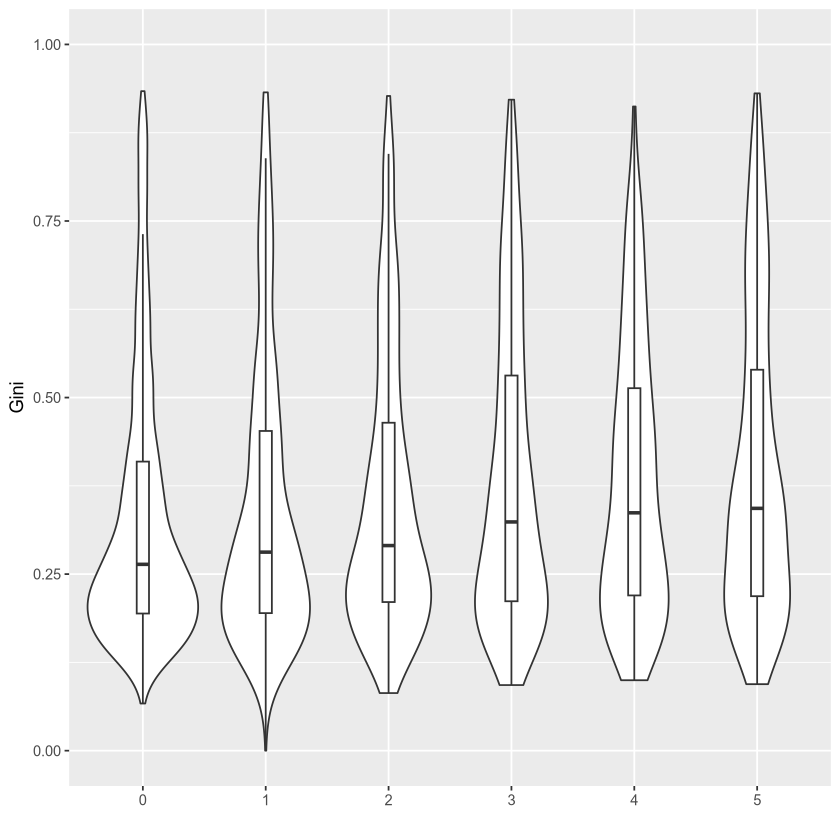

In [8]:
cellType = "Caco-2"

d = read.table(paste0("5_Biological-Spectrum/Gini/",cellType,"-By-Count-Gini.txt"))

#pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-12.",cellType,"-By-Count-Gini.pdf"), width=6, height=4)
ggplot(d, aes(x=as.character(V3), y=V2)) + geom_violin() + geom_boxplot(width = 0.1, outlier.shape=NA) + 
    ylab("Gini") + xlab("") + coord_cartesian(y=c(0,1))
#dev.off()


#### HCT116

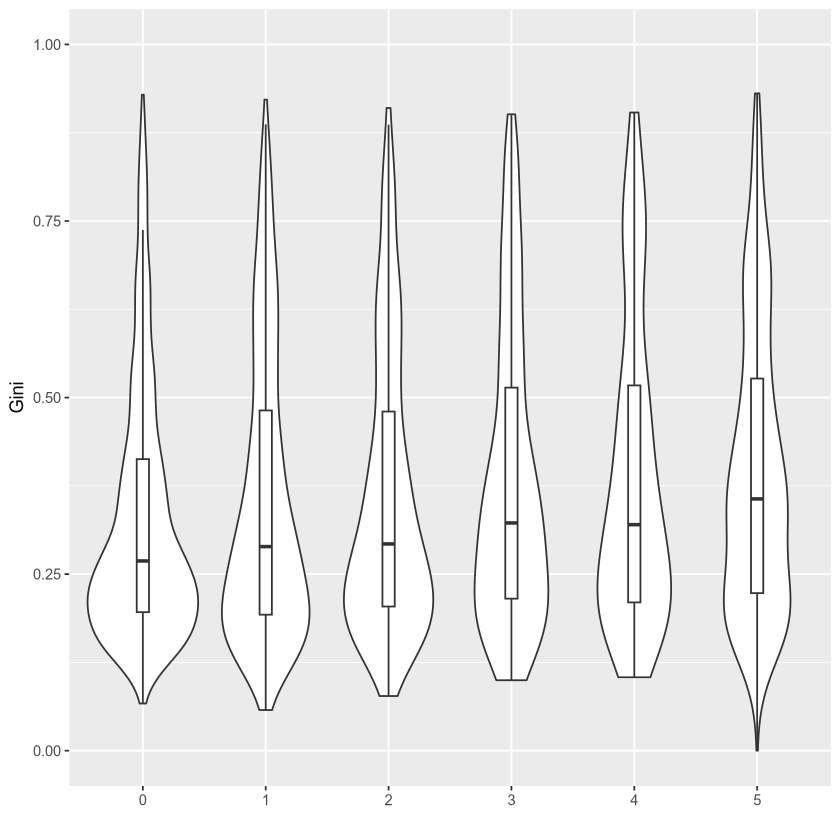

In [7]:
cellType = "HCT116"

d = read.table(paste0("5_Biological-Spectrum/Gini/",cellType,"-By-Count-Gini.txt"))

#pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-12.",cellType,"-By-Count-Gini.pdf"), width=6, height=4)
ggplot(d, aes(x=as.character(V3), y=V2)) + geom_violin() + geom_boxplot(width = 0.1, outlier.shape=NA) + 
    ylab("Gini") + xlab("") + coord_cartesian(y=c(0,1))
#dev.off()

#### HepG2

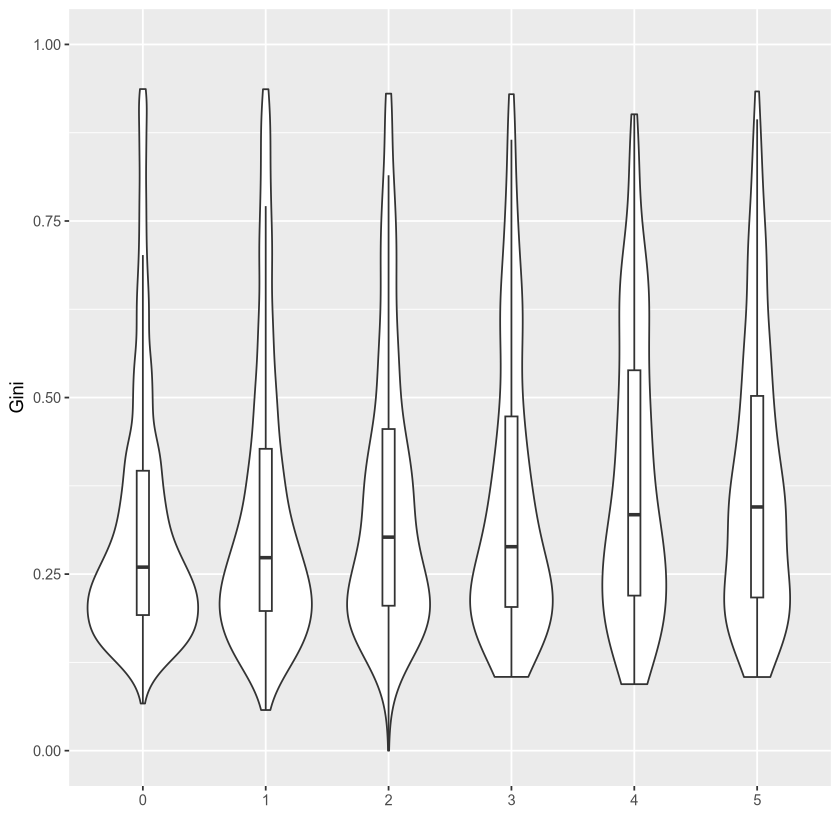

In [6]:
cellType = "HepG2"

d = read.table(paste0("5_Biological-Spectrum/Gini/",cellType,"-By-Count-Gini.txt"))

#pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-12.",cellType,"-By-Count-Gini.pdf"), width=6, height=4)
ggplot(d, aes(x=as.character(V3), y=V2)) + geom_violin() + geom_boxplot(width = 0.1, outlier.shape=NA) + 
    ylab("Gini") + xlab("") + coord_cartesian(y=c(0,1))
#dev.off()

#### K562

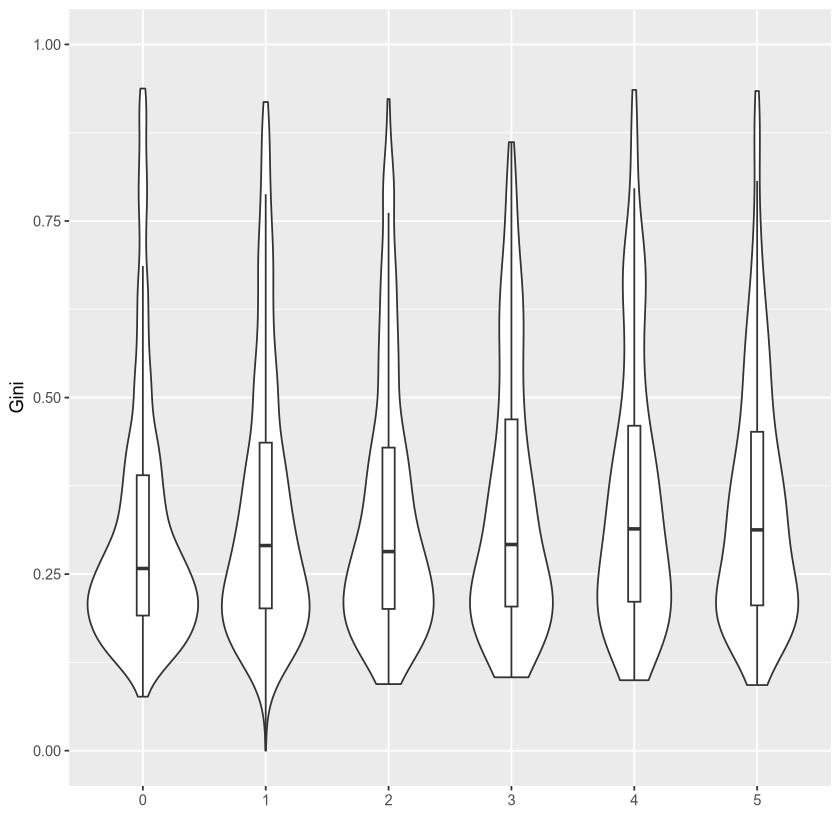

In [5]:
cellType = "K562"

d = read.table(paste0("5_Biological-Spectrum/Gini/",cellType,"-By-Count-Gini.txt"))

#pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-12.",cellType,"-By-Count-Gini.pdf"), width=6, height=4)
ggplot(d, aes(x=as.character(V3), y=V2)) + geom_violin() + geom_boxplot(width = 0.1, outlier.shape=NA) + 
    ylab("Gini") + xlab("") + coord_cartesian(y=c(0,1))
#dev.off()

#### MCF 10A

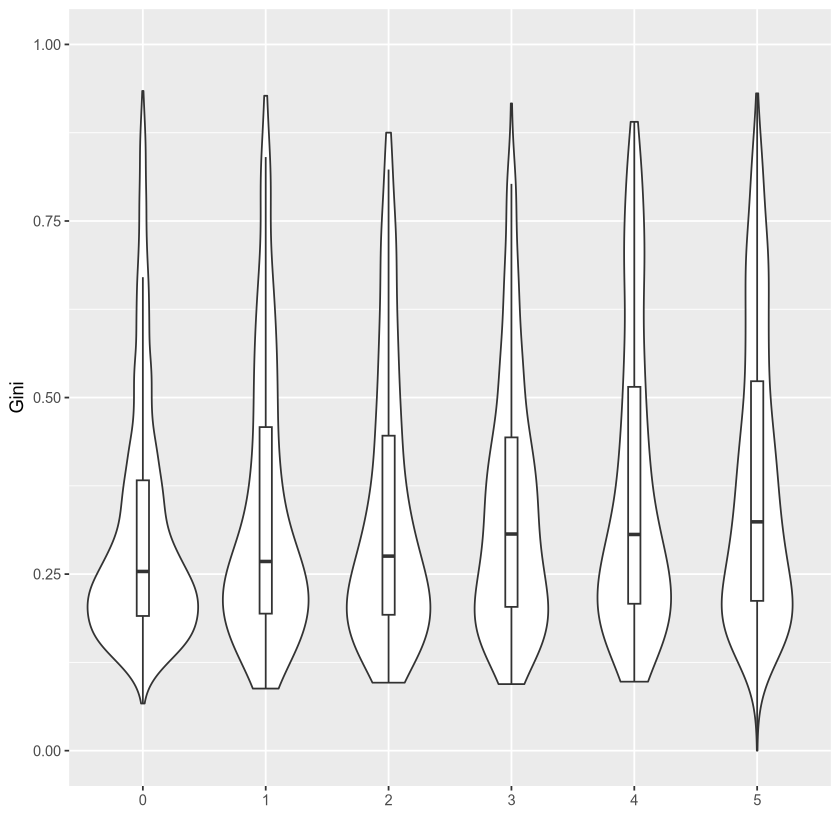

In [4]:
cellType = "MCF"

d = read.table(paste0("5_Biological-Spectrum/Gini/",cellType,"-By-Count-Gini.txt"))

#pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-12.",cellType,"-By-Count-Gini.pdf"), width=6, height=4)
ggplot(d, aes(x=as.character(V3), y=V2)) + geom_violin() + geom_boxplot(width = 0.1, outlier.shape=NA) + 
    ylab("Gini") + xlab("") + coord_cartesian(y=c(0,1))
#dev.off()

#### MCF-7

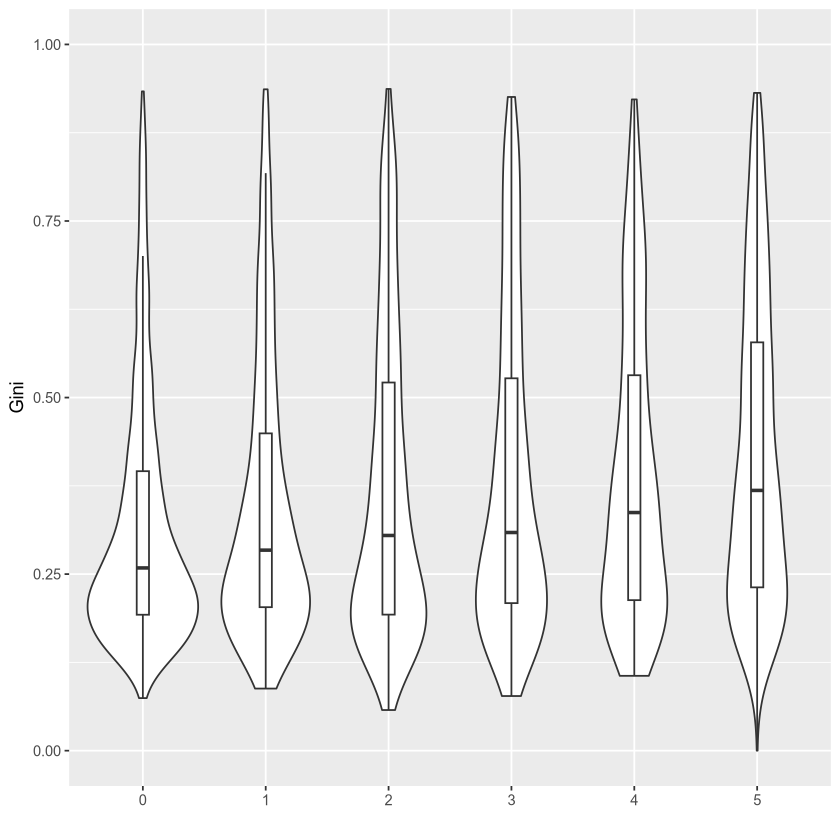

In [3]:
cellType = "MCF-7"

d = read.table(paste0("5_Biological-Spectrum/Gini/",cellType,"-By-Count-Gini.txt"))

#pdf(paste0("00_Data/Raw-Figures/Supplemental-Figure-12.",cellType,"-By-Count-Gini.pdf"), width=6, height=4)
ggplot(d, aes(x=as.character(V3), y=V2)) + geom_violin() + geom_boxplot(width = 0.1, outlier.shape=NA) + 
    ylab("Gini") + xlab("") + coord_cartesian(y=c(0,1))
#dev.off()